# Active Subspaces of Two Human Atrial Cell Models: Courtemanche (1998) and Maleckar (2009)

__Sam Coveney__ and __Richard H. Clayton__, Insigneo Institute for in-silico Medicine and Department of Computer Science, University of Sheffield, Sheffield, United Kingdom

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

This notebook analyzes the simulation runs of Coveney and Clayton [[1]](https://doi.org/10.3389/fphys.2020.00364) ("Sensitivity and Uncertainty Analysis of Two Human Atrial Cardiac Cell Models Using Gaussian Process Emulators", Front. Physiol. 11:364, 2020), which the authors published on figshare [[2]](https://doi.org/10.15131/shef.data.11309756.v1) under CC BY 4.0. Page, table and figure numbers refer to the published article. No model was rerun. The notebook runs in Python 3 with numpy, scipy and matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later, and takes about half a minute.

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import convert_data as cd

SEED = 2020                       # the only seed in this notebook (bootstrap replicates)
NBOOT = 500                       # bootstrap replicates for every estimate
TOL = 0.03                        # dimension rule (Stage 2): smallest n <= 3 with LOO R^2 >= best - TOL
t_start = time.perf_counter()
MODELS = ('courtemanche', 'maleckar')
TITLE = {'courtemanche': 'Courtemanche', 'maleckar': 'Maleckar'}
K90 = cd.QOI_NAMES.index('APD90')
NAMES = {(mo, st): cd.bounds(mo, st)[0] for mo in MODELS for st in (1, 2)}

### Summary

Coveney and Clayton [[1]](https://doi.org/10.3389/fphys.2020.00364) ran the Courtemanche (20 inputs) and Maleckar (22 inputs) models of the human atrial action potential on Latin hypercube designs that scale maximum conductances, pump and exchanger rates, Ca²⁺-handling constants, capacitance and extracellular concentrations by ±10–50 %, recorded 11 action-potential and calcium biomarkers, and computed Sobol' indices with Gaussian process emulators; a second stage repeated the study over 9 or 7 influential inputs plus the diastolic interval. From their published runs, without new simulations, we estimate active subspaces of all 11 biomarkers with a global quadratic model (QPHD) over the Stage 2 designs and choose the dimension $n$ as the smallest $n \le 3$ whose leave-one-out (LOO) $R^2$ for a cubic in $n$ active variables is within 0.03 of the best: $n = 1$ in 7 of the 22 biomarker × model cases, $n = 2$ in 13 and $n = 3$ in 2, with APD$_{90}$ one-dimensional for Maleckar ($\lambda_1/\lambda_2$ = 31.2, LOO $R^2$ 0.959) and two-dimensional for Courtemanche ($\lambda_1/\lambda_2$ = 7.5; LOO $R^2$ 0.820 with one variable, 0.915 with two). The Stage 1 designs (20 or 22 inputs, about 290 runs) are too small for a quadratic, so there we report only the direction of a global linear fit, a one-variable summary that cannot determine the dimension (for APD$_{90}$ a cubic in it has LOO $R^2$ 0.834 and 0.920), and we compare with the paper through the Sobol' indices of our fitted linear and quadratic models under the paper's Gaussian inputs, which give the paper's top input for 8 of 11 Courtemanche and 10 of 11 Maleckar Stage 1 biomarkers.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ and is nearly constant along $\mathbf W_2^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend, and a surrogate in $\mathbf y$ can replace $f$. When only values of $f$ are available, $\nabla f$ is replaced by the gradient of a fitted model (a global linear or quadratic model, or local linear fits), and the estimate is assessed with the bootstrap. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015.

### The model

**Cell models.** Both are ordinary differential equation models of a single human atrial myocyte. The membrane potential obeys

$$C_m\frac{dV}{dt} = -\Big(\sum_k I_k(V,\mathbf g,\mathbf c;\boldsymbol\theta) + I_{stim}(t)\Big),\qquad \frac{dg_j}{dt} = \frac{g_{j,\infty}(V)-g_j}{\tau_j(V)},\qquad \frac{d\mathbf c}{dt} = \mathbf J(V,\mathbf g,\mathbf c;\boldsymbol\theta),$$

where the ionic currents $I_k$ are channel currents of the form $I_k = G_k\,(\text{gating})\,(V-E_k)$ with Nernst potentials $E_k = \frac{RT}{zF}\ln(c_o/c_i)$, plus pump, exchanger and background currents; $g_j$ are gating variables and $\mathbf c$ intracellular concentrations with sarcoplasmic-reticulum uptake and release fluxes $\mathbf J$. The Courtemanche model [[3]](https://doi.org/10.1152/ajpheart.1998.275.1.H301) and the Maleckar model [[4]](https://doi.org/10.1152/ajpheart.00411.2009) (an extension of Nygren et al. [[5]](https://doi.org/10.1161/01.RES.82.1.63)) describe a similar set of currents with different formulations, Ca²⁺ handling and action-potential shapes (Sec. 2.1, p. 3). The authors ran MATLAB code generated from the CellML repository, solved with `ode15s` (relative and absolute tolerance $10^{-6}$, maximum step 0.5 ms). In the Courtemanche model they fixed $[\mathrm{Na}^+]_i$ and $[\mathrm{K}^+]_i$ at 11.17 and 139.00 mM to avoid drift; in the Maleckar model they set $I_{K,ACh} = 0$ (Sec. 2.3, p. 4).

**Protocol.** The stimulus was 2000 pA for 2 ms (Courtemanche) and, as printed, "750/$C_m$ pA/pF for 6 ms" (Maleckar). **Stage 1:** 40 beats at a cycle length of 1000 ms, biomarkers from the last beat. **Stage 2:** 39 S1 beats at 1000 ms, then an S2 stimulus at the APD$_{90}$ of the last S1 beat plus 10 ms plus a diastolic interval DI, which is an extra input on [50, 450] ms; the S2 beat is analyzed (Secs. 2.3 and 3.2, pp. 4 and 8).

**Quantities of interest** (Sec. 2.2, p. 4): $dV_m/dt_{max}$, $V_{max}$, the voltages $V_{20}, V_{40}, V_{60}, V_{80}$ at 20–80 % of APD$_{90}$, APD$_{50}$ and APD$_{90}$, the resting potential (mean over 10 ms, 100 ms before the upstroke), and the minimum and maximum of $[\mathrm{Ca}^{2+}]_i$. The paper and the data do not state units; from the values they are V/s, mV, ms and mM. Our headline biomarker is APD$_{90}$, the one the paper analyzes most (Figs. 6, 9, 11, 12); the others are summarized in one table.

**Runs and removals.** Stage 1 is an optimized Latin hypercube of 300 runs per model; runs with pacemaking, resting potential above −60 mV, APD$_{90}$ above 600 ms, or alternans (APD$_{90}$ of beats 39 and 40 differing by more than 5 %) were removed: 5 Courtemanche and 14 Maleckar runs. Stage 2 is a Latin hypercube of 200 runs over the reduced inputs, with the others at their central values; 0 Courtemanche and 5 Maleckar runs were removed (Sec. 2.5, pp. 4–5). The published files hold the kept runs only: 295, 286, 200 and 195 rows.

**Inputs.** The inputs vary by ±50 % about the model defaults, except $G_{K1}$ and $C_m$ (±25 %) and the extracellular concentrations (±10 %) (Sec. 2.5). Table 1 (p. 3) has misprints, so the design ranges below are those of the data. A 300-point Latin hypercube puts exactly one point in each 1/300 stratum of each input; with the right bounds the stored Stage 1 columns show this pattern, except where removed runs or the six-decimal print precision hide it. We take the stated percentage about Table 1's central value where the data agree, and otherwise the central value that restores the stratum pattern (column "note"). Three corrections are large: the Courtemanche $K_{rel}$ data are 100 times the printed range (centre 30, not 0.30 ms⁻¹), the Maleckar $K_{NaCa}$ centre is 0.0375, half the printed 0.0750, and the Maleckar background Ca²⁺ conductance $G_{bCa}$ spans 0.0079–0.0865 nS, not ±50 % of 0.0590 (0.0295–0.0885). A CellML encoding of the Maleckar model (the Chaste copy of the Physiome Model Repository file, see `DATA.md`) has $g_{B,Ca}$ = 0.078681 nS, the Nygren et al. value, and $K_{NaCa}$ = 0.0374842 pA/mM⁴: the $K_{NaCa}$ data centre is the model default, and the $G_{bCa}$ range is 0.1–1.1 × the default, so Table 1's 0.0590 is probably wrong and this input was sampled −90 %/+10 % about its default. The refined Courtemanche centres ($G_{to}$ 0.1652, $G_{Kr}$ 0.029412, $G_{Ks}$ 0.12941, $G_{CaL}$ 0.12375, $G_{bNa}$ 0.00067444, $I_{NaK,max}$ 0.59933, $K_{rel}$ 30 ms⁻¹) look like the Courtemanche (1998) defaults that Table 1 rounds; we have not checked them against a CellML file. The figshare description says the inputs are "normalised to vary between 0 and 1"; the files are in fact in physical units.

In [2]:
for model in MODELS:
    print(f'{TITLE[model]} model, Stage 1 inputs (Table 1 of [1], p. 3). Design range used: centre x (1 -/+ fraction).')
    print(f"{'input':10s} {'units':8s} {'Table 1':>9s}  {'printed range':<26s}| {'lower':>10s} {'upper':>10s}  note")
    for r in cd.inputs(model, 1):
        tr = r['table_range'].split(',  ')[0] if len(r['table_range']) < 27 else r['table_range'][:24] + '..'
        print(f"{r['name']:10s} {r['units']:8s} {r['table_central']:9.4g}  {tr:<26s}| {r['lower']:10.5g} {r['upper']:10.5g}  {r['note']}")
    print()
print('Stage 2 inputs (Sec. 3.2 and Figs. 7-8 of [1]); the other inputs are held at their Table 1 centre:')
for model in MODELS:
    names, lo, hi = cd.bounds(model, 2)
    print(f'  {TITLE[model]:12s} ' + ', '.join(names) + f'   (DI in [{lo[-1]:g}, {hi[-1]:g}] ms)')

Courtemanche model, Stage 1 inputs (Table 1 of [1], p. 3). Design range used: centre x (1 -/+ fraction).
input      units      Table 1  printed range             |      lower      upper  note
GNa        nS/pF          7.8  5.85-11.70 (+-50%)        |        3.9       11.7  printed lower end is 0.75x centre
GK1        nS/pF         0.09  0.045-0.018 (+-25%)       |     0.0675     0.1125  printed range misprinted
Gto        nS/pF        0.165  0.0826-0.0330 (+-50%)     |     0.0826     0.2478  printed range misprinted; data reach 0.2476 > 1.5 x 0.165
fGKur      1                1  0.50-1.50 (+-50%)         |        0.5        1.5  
GKr        nS/pF       0.0294  0.0147-0.0441 (+-50%)     |   0.014706   0.044118  centre refined from the LHS strata
GKs        nS/pF       0.1294  0.0647-0.1941 (+-50%)     |   0.064705    0.19411  centre refined from the LHS strata
GCaL       nS/pF       0.1237  0.0619-0.1856 (+-50%)     |   0.061875    0.18562  data reach 0.185619 > 1.5 x 0.1237
GbNa       

Stage 2 keeps the inputs whose Stage 1 first-order index exceeded 0.1, minus the Na⁺ conductances, the extracellular concentrations and the Ca²⁺ storage, uptake and release constants (Sec. 3.2, p. 8). The text lists eight Courtemanche inputs; the data file and Figs. 7A and 8A also have $G_{Kr}$, so Stage 2 has $m = 10$ inputs for Courtemanche (with DI) and $m = 8$ for Maleckar.

### Load data

`convert_data.py` copied the eight figshare text files into CSV files without changing a digit (see `DATA.md`). Inputs are in physical units, one run per row; the outputs file of each model and stage has the same rows.

In [3]:
X, F = {}, {}
for model in MODELS:
    for stage in (1, 2):
        X[model, stage] = np.loadtxt(cd.csv_name(model, stage, 'inputs'), delimiter=',')
        F[model, stage] = np.loadtxt(cd.csv_name(model, stage, 'outputs'), delimiter=',')
        print(f'{TITLE[model]:12s} Stage {stage}: inputs {X[model, stage].shape}, outputs {F[model, stage].shape}')

Courtemanche Stage 1: inputs (295, 20), outputs (295, 11)
Courtemanche Stage 2: inputs (200, 10), outputs (200, 11)
Maleckar     Stage 1: inputs (286, 22), outputs (286, 11)
Maleckar     Stage 2: inputs (195, 8), outputs (195, 11)


#### Checks on the design and the outputs

We declare each design as a uniform space on the ranges above (the library maps every input to $[-1, 1]$ by its own range; all inputs are scaled the same way), and check that every row lies inside, how many columns show the one-point-per-stratum pattern, and whether any kept run violates the paper's removal rules or is unphysical.

In [4]:
space = {}
for model in MODELS:
    for stage in (1, 2):
        names, lo, hi = cd.bounds(model, stage)
        space[model, stage] = ac.Uniform(lo, hi, names=names)
        Xs, Fs = X[model, stage], F[model, stage]
        N = 300 if stage == 1 else 200                    # runs in the design before removals (Sec. 2.5)
        u = (Xs - lo) / (hi - lo)
        strata = np.array([len(np.unique(np.floor(u[:, j] * N))) for j in range(len(names))])
        q = {n: Fs[:, i] for i, n in enumerate(cd.QOI_NAMES)}
        print(f'{TITLE[model]} Stage {stage}: rows inside the design box {np.all((u >= 0) & (u <= 1))}; '
              f'u in [{u.min():.4f}, {u.max():.4f}]; columns with one point per 1/{N} stratum: '
              f'{np.sum(strata == len(Xs))} of {len(names)} (fewest: {strata.min()} of {len(Xs)}, {names[strata.argmin()]})')
        print(f'   removal criteria of Sec. 2.5 violated: RestVm > -60 mV: {np.sum(q["RestVm"] > -60)}, '
              f'APD90 > 600 ms: {np.sum(q["APD90"] > 600)};  non-positive Ca: {np.sum(Fs[:, 9:] <= 0)};  '
              f'APD50 >= APD90: {np.sum(q["APD50"] >= q["APD90"])};  non-positive inputs: {np.sum(Xs <= 0)}')
        print(f'   distinct values: Ca_min {len(np.unique(q["Ca_min"]))}, Ca_max {len(np.unique(q["Ca_max"]))} of {len(Xs)} '
              f'(written with 6 decimals: Ca_min {q["Ca_min"].min():.6f}-{q["Ca_min"].max():.6f} mM)')

Courtemanche Stage 1: rows inside the design box True; u in [0.0002, 1.0000]; columns with one point per 1/300 stratum: 11 of 20 (fewest: 268 of 295, GbNa)
   removal criteria of Sec. 2.5 violated: RestVm > -60 mV: 0, APD90 > 600 ms: 0;  non-positive Ca: 0;  APD50 >= APD90: 0;  non-positive inputs: 0
   distinct values: Ca_min 115, Ca_max 251 of 295 (written with 6 decimals: Ca_min 0.000044-0.000236 mM)
Courtemanche Stage 2: rows inside the design box True; u in [0.0000, 0.9996]; columns with one point per 1/200 stratum: 7 of 10 (fewest: 192 of 200, GbCa)
   removal criteria of Sec. 2.5 violated: RestVm > -60 mV: 0, APD90 > 600 ms: 0;  non-positive Ca: 0;  APD50 >= APD90: 0;  non-positive inputs: 0
   distinct values: Ca_min 90, Ca_max 173 of 200 (written with 6 decimals: Ca_min 0.000072-0.000236 mM)
Maleckar Stage 1: rows inside the design box True; u in [0.0000, 0.9999]; columns with one point per 1/300 stratum: 17 of 22 (fewest: 190 of 286, Kcyca)
   removal criteria of Sec. 2.5 vio

All rows are inside their design boxes. In 11 of 20 (Courtemanche) and 17 of 22 (Maleckar) Stage 1 columns, and in 7 of 10 and 7 of 8 Stage 2 columns, every point sits in its own stratum, which confirms the Latin hypercubes and the inferred bounds; the other columns have small values whose six printed decimals are coarser than a stratum (e.g. the Maleckar $K_{cyca}$, 0.00015–0.00045 mM, 190 distinct strata) or a bound that the stored points do not pin down. No kept run violates the removal rules, no input is non-positive, and no calcium value is non-positive, so no row is dropped. The six-decimal precision matters for one output: $\mathrm{Ca}_{min}$ has only 72–115 distinct values (1–3 significant digits; e.g. the Maleckar Stage 1 minimum is 0.000007 mM), so its smallest scales are quantized.

### Estimate the subspace

The published data have values only; no gradients. The global quadratic estimator (QPHD) fits $q(\mathbf x) = c + \mathbf g^T\mathbf x + \tfrac12\mathbf x^T\mathbf H\mathbf x$ in the normalized inputs, which has $(m+1)(m+2)/2$ coefficients, and our rule asks for at least twice as many runs. The cell below checks this for each design, and compares the leave-one-out (LOO) $R^2$ of a linear and a quadratic least-squares fit of APD$_{90}$.

In [5]:
loo = lambda Xs, f, sp, deg: ac.fit_surrogate(X=Xs, f=f, space=sp, subspace=None, kind='poly', degree=deg).loo_r_squared
for model in MODELS:
    for stage in (1, 2):
        M, m = X[model, stage].shape
        nq = (m + 1) * (m + 2) // 2
        f = F[model, stage][:, K90]
        print(f'{TITLE[model]:12s} Stage {stage}: m = {m:2d}, M = {M}, quadratic terms {nq:3d}, 2 x terms {2 * nq:3d} -> '
              f'{"QPHD" if M >= 2 * nq else "too few runs for QPHD"};  APD90 LOO R^2: linear {loo(X[model, stage], f, space[model, stage], 1):.3f}, '
              f'quadratic {loo(X[model, stage], f, space[model, stage], 2):.3f}')

Courtemanche Stage 1: m = 20, M = 295, quadratic terms 231, 2 x terms 462 -> too few runs for QPHD;  APD90 LOO R^2: linear 0.803, quadratic 0.672
Courtemanche Stage 2: m = 10, M = 200, quadratic terms  66, 2 x terms 132 -> QPHD;  APD90 LOO R^2: linear 0.797, quadratic 0.919
Maleckar     Stage 1: m = 22, M = 286, quadratic terms 276, 2 x terms 552 -> too few runs for QPHD;  APD90 LOO R^2: linear 0.835, quadratic -0.835
Maleckar     Stage 2: m =  8, M = 195, quadratic terms  45, 2 x terms  90 -> QPHD;  APD90 LOO R^2: linear 0.925, quadratic 0.983


**Stage 1 has too few runs for QPHD**: 231 and 276 coefficients would need 462 and 552 runs, and there are 295 and 286. The quadratic fits confirm it: their LOO $R^2$ for APD$_{90}$ (0.672 Courtemanche, −0.835 Maleckar) is below that of the linear fits (0.803, 0.835), the sign of overfitting. The two stages cannot be pooled, because Stage 2 holds 10 or 14 inputs at their central values, adds DI and uses a different pacing protocol: a different design space and a different function. So:

- **Stage 1 ($m$ = 20, 22): global linear model** (`estimator="ols"`, $n = 1$ by construction). The direction $\mathbf w_1 = \hat{\mathbf u}/\lVert\hat{\mathbf u}\rVert$ is the normalized gradient of the least-squares linear fit, the active subspace of the linear approximation. It is a one-variable summary, labelled as such throughout: a linear fit has a rank-one $\mathbf C$, so it cannot show whether a second direction matters, and **Stage 1 cannot determine the subspace dimension**. Two checks show how much the summary misses. (a) A **partial quadratic**, quadratic in the 9 (Courtemanche) or 7 (Maleckar) model inputs kept in Stage 2 and linear in the others (66 and 51 coefficients), which the Stage 1 runs can support; its LOO $R^2$ and its $\mathbf C = \mathbf g\mathbf g^T + \tfrac13\mathbf H^2$ are diagnostics that depend on which inputs are allowed curvature, not estimates of the spectrum of the biomarker. (b) **Local linear gradients** (a linear fit through the $p$ nearest runs of each run), shown only to document that their eigenvalue ratio is set by $p$ and is unreliable here.
- **Stage 2 ($m$ = 10, 8): QPHD.** 66 and 45 coefficients need 132 and 90 runs; there are 200 and 195. The library returns $\mathbf C = \mathbf g\mathbf g^T + \mathbf H\boldsymbol\Sigma\mathbf H$ with $\boldsymbol\Sigma = \tfrac13\mathbf I$, exactly $\int\nabla q\,\nabla q^T\rho\,d\mathbf x$ for the fitted quadratic and the uniform density on the cube.

**Dimension rule (Stage 2).** The library's default eigenvalue-gap rule (`EVG(gap="linear")`) picks $n = 1$ whenever $\lambda_1 - \lambda_2 > \lambda_2 - \lambda_3$, which holds almost automatically once $\lambda_1 > 2\lambda_2$, so we do not use it. Instead, for each biomarker we fit a cubic polynomial in $n = 1, 2, 3$ QPHD active variables and take **the smallest $n$ whose LOO $R^2$ is within `TOL` = 0.03 of the best of the three**; $n = 3$ means "at least 3" within the range examined. We report the eigenvalue ratios with bootstrap intervals beside it.

The library warns (`ValidityWarning`) that OLS and QPHD estimate $\mathbb E[\nabla f]$ and $\mathbb E[\nabla^2 f]$ only for Gaussian inputs; here we use them as the active subspace of the fitted linear or quadratic model, so we record the warning and go on. All bootstraps use `NBOOT` = 500 replicates and the seed `SEED`, and eigenvector signs are set so that the biomarker increases along $\mathbf w_1$.

### Results, Stage 1: APD$_{90}$ over all 20 or 22 inputs

In [6]:
def capture(fn, **kw):
    """Run fn(**kw) and return its result and the distinct warning messages it raised."""
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        res = fn(**kw)
    return res, sorted({f'{type(w.message).__name__}: {w.message}' for w in caught})

def partial_quadratic(Z, f, S):
    """Least-squares fit in normalized inputs Z, quadratic in the columns S and linear in all columns.
    Returns the design matrix, the coefficients and the (i, j) index pairs of the quadratic terms."""
    pairs = [(i, j) for a, i in enumerate(S) for j in S[a:]]
    A = np.column_stack([np.ones(len(Z))] + [Z[:, i] for i in range(Z.shape[1])] + [Z[:, i] * Z[:, j] for i, j in pairs])
    return A, np.linalg.lstsq(A, f, rcond=None)[0], pairs

def grad_hess(c, m, pairs):
    """Gradient at 0 and Hessian of the fitted polynomial c[0] + g.z + sum_{(i,j)} a_ij z_i z_j."""
    H = np.zeros((m, m))
    for (i, j), a in zip(pairs, c[m + 1:]):
        if i == j:
            H[i, i] = 2 * a
        else:
            H[i, j] = H[j, i] = a
    return c[1:m + 1], H

def quad_eigenvalues(c, m, pairs):
    """Eigenvalues, descending, of C = g g^T + H^2/3 = E[grad q grad q^T] for z uniform on [-1, 1]^m."""
    g, H = grad_hess(c, m, pairs)
    return np.linalg.eigvalsh(np.outer(g, g) + H @ H / 3)[::-1]

def loo_lstsq(A, f):
    """Leave-one-out R^2 of the least-squares fit with design matrix A (hat-matrix formula)."""
    Q, _ = np.linalg.qr(A)
    e = (f - Q @ (Q.T @ f)) / (1 - np.sum(Q ** 2, axis=1))
    return 1 - np.sum(e ** 2) / np.sum((f - f.mean()) ** 2)

ols, pq, cub1_s1, msgs = {}, {}, {}, set()
rng = np.random.default_rng(SEED)
t0 = time.perf_counter()
for model in MODELS:
    sp, Xs, f = space[model, 1], X[model, 1], F[model, 1][:, K90]
    ols[model], w = capture(ac.active_subspace, space=sp, X=Xs, f=f, estimator='ols', n=1,
                            nboot=NBOOT, bootstrap_vectors=1, rng=SEED)
    msgs.update(w)
    cub1_s1[model] = ac.fit_surrogate(X=Xs, f=f, subspace=ols[model], kind='poly', degree=3).loo_r_squared
    Z, m = sp.to_normalized(Xs), Xs.shape[1]
    subsets = {'Stage 2 inputs': [NAMES[model, 1].index(n) for n in NAMES[model, 2][:-1]],
               'top 10 |w1|': sorted(np.argsort(-np.abs(ols[model].W[:, 0]))[:10])}
    pq[model] = {}
    for label, S in subsets.items():
        A, c, pairs = partial_quadratic(Z, f, S)
        boot = []
        for _ in range(NBOOT):
            i = rng.integers(0, len(f), len(f))
            boot.append(quad_eigenvalues(np.linalg.lstsq(A[i], f[i], rcond=None)[0], m, pairs))
        pq[model][label] = dict(ncoef=A.shape[1], loo=loo_lstsq(A, f), lam=quad_eigenvalues(c, m, pairs), boot=np.array(boot))
print(f'OLS and partial quadratic, {NBOOT} bootstrap replicates each: {time.perf_counter() - t0:.1f} s')
for m_ in sorted(msgs):
    print(m_[:200])
for model in MODELS:
    print(f'{TITLE[model]:12s} APD90, Stage 1. OLS lambda_1 = ||u||^2 = {ols[model].eigenvalues[0]:.4g} (ms^2, u in [-1,1]^m). LOO R^2: '
          f'linear in all inputs {loo(X[model, 1], F[model, 1][:, K90], space[model, 1], 1):.3f}; '
          f'cubic in the OLS variable y1 (one-variable summary) {cub1_s1[model]:.3f}')
    for label, r in pq[model].items():
        lam, B = r['lam'], r['boot']
        i12 = np.percentile(B[:, 0] / B[:, 1], [2.5, 97.5])
        print(f'{"":12s} partial quadratic, quadratic in {label:14s} ({r["ncoef"]} coefficients): LOO R^2 {r["loo"]:.3f}; '
              f'its lambda_1/lambda_2 = {lam[0] / lam[1]:.1f} [{i12[0]:.1f}, {i12[1]:.1f}], lambda_2/lambda_3 = {lam[1] / lam[2]:.2f}')

OLS and partial quadratic, 500 bootstrap replicates each: 3.8 s
Courtemanche APD90, Stage 1. OLS lambda_1 = ||u||^2 = 1.066e+04 (ms^2, u in [-1,1]^m). LOO R^2: linear in all inputs 0.803; cubic in the OLS variable y1 (one-variable summary) 0.834
             partial quadratic, quadratic in Stage 2 inputs (66 coefficients): LOO R^2 0.879; its lambda_1/lambda_2 = 5.5 [3.9, 7.2], lambda_2/lambda_3 = 4.06
             partial quadratic, quadratic in top 10 |w1|    (76 coefficients): LOO R^2 0.871; its lambda_1/lambda_2 = 6.5 [4.2, 9.0], lambda_2/lambda_3 = 4.58
Maleckar     APD90, Stage 1. OLS lambda_1 = ||u||^2 = 8545 (ms^2, u in [-1,1]^m). LOO R^2: linear in all inputs 0.835; cubic in the OLS variable y1 (one-variable summary) 0.920
             partial quadratic, quadratic in Stage 2 inputs (51 coefficients): LOO R^2 0.867; its lambda_1/lambda_2 = 40.1 [15.8, 40.1], lambda_2/lambda_3 = 1.29
             partial quadratic, quadratic in top 10 |w1|    (78 coefficients): LOO R^2 0.896; its

The warning is the validity warning discussed above. For APD$_{90}$ the one-variable summary (a cubic in the OLS active variable) has LOO $R^2$ = 0.834 (Courtemanche) and 0.920 (Maleckar), against 0.803 and 0.835 for the linear model in all inputs. For **Courtemanche** the partial quadratic in the Stage 2 inputs does better than the one-variable summary (LOO $R^2$ 0.879 against 0.834), and its fitted $\mathbf C$ has $\lambda_1/\lambda_2$ = 5.5 [3.9, 7.2] (6.5 when the curvature is put on the ten largest OLS inputs instead): within this model class a second direction is not negligible. For **Maleckar** the partial quadratic does worse than the one-variable summary (0.867 against 0.920), so its convex APD$_{90}$ trend involves curvature in inputs outside the Stage 2 set, and its $\lambda_1/\lambda_2$ (40.1, or 28.7 with the other subset) is a large ratio for an incomplete model. Neither ratio is an estimate of the APD$_{90}$ spectrum: Stage 1 cannot determine the subspace dimension, and Stage 2 below is where we choose it.

**Partial-quadratic eigenvalues** (curvature in the Stage 2 inputs) with 95 % bootstrap bands; the black cross is the OLS $\lambda_1$. The fitted $\mathbf C$ has rank at most 10 (Courtemanche) or 8 (Maleckar), the number of curved inputs plus one; only the nonzero eigenvalues are shown.

Courtemanche partial quadratic (Stage 2 inputs): lambda_1..3 = 1.212e+04, 2205, 543.8; lambda_2/lambda_3 95% interval [2.01, 5.67];  OLS direction: bootstrap mean subspace distance 0.123
Maleckar     partial quadratic (Stage 2 inputs): lambda_1..3 = 9122, 227.5, 176; lambda_2/lambda_3 95% interval [1.08, 2.86];  OLS direction: bootstrap mean subspace distance 0.105


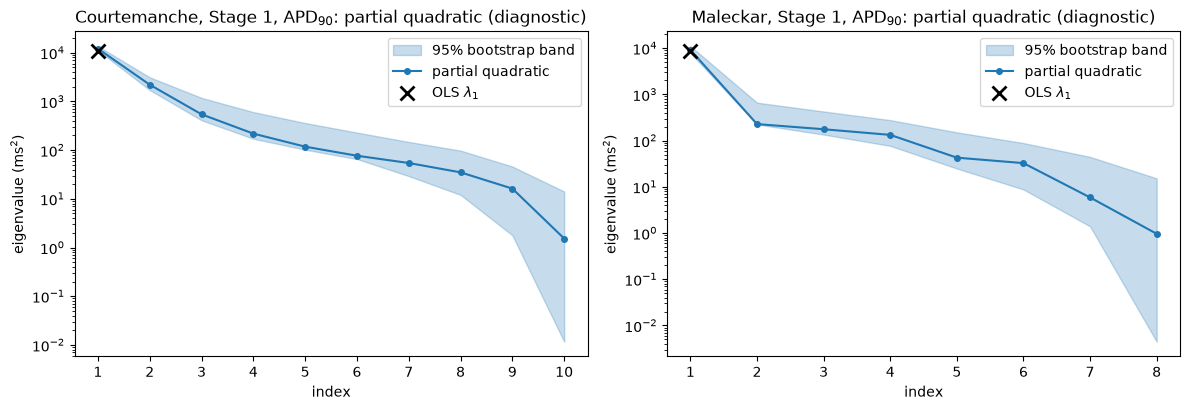

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, model in zip(axes, MODELS):
    r = pq[model]['Stage 2 inputs']
    rank = int(np.sum(r['lam'] > 1e-10 * r['lam'][0]))      # C has rank <= (number of curved inputs) + 1; the rest are zero
    k = np.arange(1, rank + 1)
    lo_, hi_ = np.percentile(r['boot'][:, :rank], [2.5, 97.5], axis=0)
    ax.fill_between(k, lo_, hi_, color='C0', alpha=0.25, label='95% bootstrap band')
    ax.semilogy(k, r['lam'][:rank], 'o-', color='C0', ms=4, label='partial quadratic')
    ax.set_xticks(k)
    ax.plot([1], [ols[model].eigenvalues[0]], 'kx', ms=10, mew=2, label=r'OLS $\lambda_1$')
    ax.set_xlabel('index'); ax.set_ylabel('eigenvalue (ms$^2$)')
    ax.set_title(f'{TITLE[model]}, Stage 1, APD$_{{90}}$: partial quadratic (diagnostic)')
    ax.legend()
fig.tight_layout()
plt.close(fig)
for model in MODELS:
    r = pq[model]['Stage 2 inputs']
    B = r['boot']
    i23 = np.percentile(B[:, 1] / B[:, 2], [2.5, 97.5])
    print(f'{TITLE[model]:12s} partial quadratic (Stage 2 inputs): lambda_1..3 = {r["lam"][0]:.4g}, {r["lam"][1]:.4g}, {r["lam"][2]:.4g}; '
          f'lambda_2/lambda_3 95% interval [{i23[0]:.2f}, {i23[1]:.2f}];  OLS direction: bootstrap mean subspace distance '
          f'{ols[model].bootstrap_distances.mean(axis=0)[0]:.3f}')
fig

The partial-quadratic $\lambda_1$ (1.212 × 10⁴ and 9122 ms²) is close to the OLS $\lambda_1$ (1.066 × 10⁴ and 8545 ms²), so the dominant direction is robust; what the Stage 1 runs leave open is the size of $\lambda_2$ relative to $\lambda_1$. The OLS direction itself is stable under resampling (bootstrap mean subspace distance 0.123 and 0.105).

**Local linear gradients depend on the neighbour count.** The library's other value-only estimator fits a plane through the $p$ nearest runs of each run (default $p = \lfloor 1.7m\rfloor$ = 34 or 37). The cell below computes its $\lambda_1/\lambda_2$ for APD$_{90}$ as $p$ varies, and for a synthetic test function with a known answer on the same Courtemanche Stage 1 design: the quadratic fitted to the Courtemanche Stage 2 APD$_{90}$ runs, placed on the 9 shared inputs, whose exact uniform-measure $\lambda_1/\lambda_2$ is known.

Courtemanche APD90               local linear lambda_1/lambda_2: p = 25: 9.0, p = 34: 24.1, p = 50: 35.1, p = 80: 53.8, p = 120: 85.1, p = 200: 241.0


Maleckar APD90                   local linear lambda_1/lambda_2: p = 25: 4.1, p = 37: 46.3, p = 50: 75.3, p = 80: 150.5, p = 120: 251.2, p = 200: 813.6


synthetic (Courtemanche design)  local linear lambda_1/lambda_2: p = 25: 14.3, p = 34: 42.8, p = 50: 68.4, p = 80: 95.9, p = 120: 151.8, p = 200: 445.3
synthetic test function: exact lambda_1/lambda_2 = 7.86, lambda_2/lambda_3 = 4.80
Courtemanche Stage 1 design in [-1,1]^20: median distance from a run to its 34th nearest run (itself included) 3.07; median distance between runs 3.63


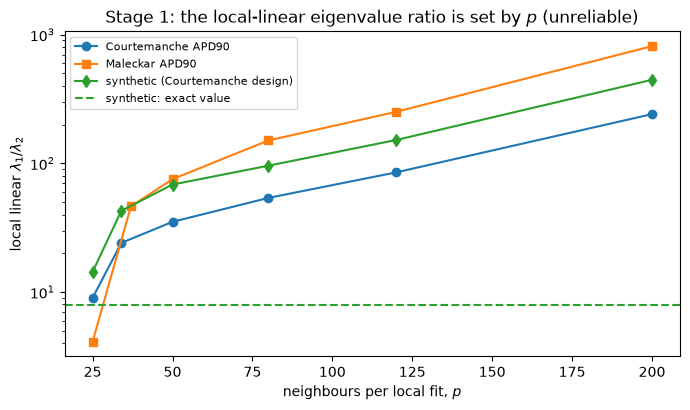

In [8]:
Z1 = space['courtemanche', 1].to_normalized(X['courtemanche', 1])
Z2 = space['courtemanche', 2].to_normalized(X['courtemanche', 2])
m1, m2 = Z1.shape[1], Z2.shape[1]
_, c2, pairs2 = partial_quadratic(Z2, F['courtemanche', 2][:, K90], list(range(m2)))      # full quadratic in Stage 2
g2, H2 = grad_hess(c2, m2, pairs2)
idx = [NAMES['courtemanche', 1].index(n) for n in NAMES['courtemanche', 2][:-1]]          # the 9 shared inputs (DI dropped)
g_syn, H_syn = np.zeros(m1), np.zeros((m1, m1))
g_syn[idx], H_syn[np.ix_(idx, idx)] = g2[:-1], H2[:-1, :-1]
f_syn = Z1 @ g_syn + 0.5 * np.einsum('ij,jk,ik->i', Z1, H_syn, Z1)
lam_syn = np.linalg.eigvalsh(np.outer(g_syn, g_syn) + H_syn @ H_syn / 3)[::-1]

def ll_ratio(Xs, f, sp, p):
    G = ac.local_linear_gradients(X=Xs, f=f, space=sp, p=p).grads
    lam = np.linalg.eigvalsh(G.T @ G / len(G))[::-1]
    return lam[0] / lam[1]

cases = {'Courtemanche APD90': ('courtemanche', F['courtemanche', 1][:, K90]),
         'Maleckar APD90': ('maleckar', F['maleckar', 1][:, K90]),
         'synthetic (Courtemanche design)': ('courtemanche', f_syn)}
ll_curve = {}
for label, (model, f) in cases.items():
    m = X[model, 1].shape[1]
    ps = sorted({25, int(1.7 * m), 50, 80, 120, 200})
    ll_curve[label] = (ps, [ll_ratio(X[model, 1], f, space[model, 1], p) for p in ps])
    print(f'{label:32s} local linear lambda_1/lambda_2: ' + ', '.join(f'p = {p}: {r:.1f}' for p, r in zip(*ll_curve[label])))
print(f'synthetic test function: exact lambda_1/lambda_2 = {lam_syn[0] / lam_syn[1]:.2f}, lambda_2/lambda_3 = {lam_syn[1] / lam_syn[2]:.2f}')
D = np.sqrt(((Z1[:, None, :] - Z1[None, :, :]) ** 2).sum(-1))
print(f'Courtemanche Stage 1 design in [-1,1]^20: median distance from a run to its 34th nearest run (itself included) '
      f'{np.median(np.sort(D, axis=1)[:, 33]):.2f}; median distance between runs {np.median(D[np.triu_indices(len(D), 1)]):.2f}')
fig, ax = plt.subplots(figsize=(7, 4.2))
for (label, (ps, rs)), mk in zip(ll_curve.items(), 'osd'):
    ax.semilogy(ps, rs, mk + '-', label=label)
ax.axhline(lam_syn[0] / lam_syn[1], color='C2', ls='--', label='synthetic: exact value')
ax.set_xlabel('neighbours per local fit, $p$'); ax.set_ylabel(r'local linear $\lambda_1/\lambda_2$')
ax.set_title('Stage 1: the local-linear eigenvalue ratio is set by $p$ (unreliable)')
ax.legend(fontsize=8)
fig.tight_layout()
plt.close(fig)
fig

The local-linear ratio grows steadily with $p$, from 9.0 to 241.0 for Courtemanche and from 4.1 to 813.6 for Maleckar, and at the default $p$ it is 24.1 and 46.3. On the synthetic function, whose exact $\lambda_1/\lambda_2$ is 7.86, it reports 42.8 at the default $p$ = 34. With 34 neighbours among 295 runs in 20 dimensions the median distance to the 34th nearest run (3.07) is close to the median distance between runs (3.63): each "local" plane is nearly a global fit, the gradients are smoothed, and $\lambda_2, \lambda_3, \dots$ shrink with them. The local-linear eigenvalue ratio therefore measures the neighbourhood size, not the model, and we do not report it as an eigenvalue ratio.

**Eigenvectors.** The OLS direction with its 95 % bootstrap band.

Courtemanche w1 (APD90 increases along w1): INaKmax -0.424, GbCa +0.402, GCaL +0.393, GKr -0.381, IpCamax -0.361, GK1 -0.290, INaCamax +0.204
             share of |w1|^2 in the top 5: 0.772; components whose 95% band excludes 0: 14 of 20
Maleckar     w1 (APD90 increases along w1): GbCa +0.462, GK1 -0.409, GKur -0.386, GCaL +0.358, Cm +0.355, Kxcs -0.263, GbNa +0.178
             share of |w1|^2 in the top 5: 0.784; components whose 95% band excludes 0: 19 of 22


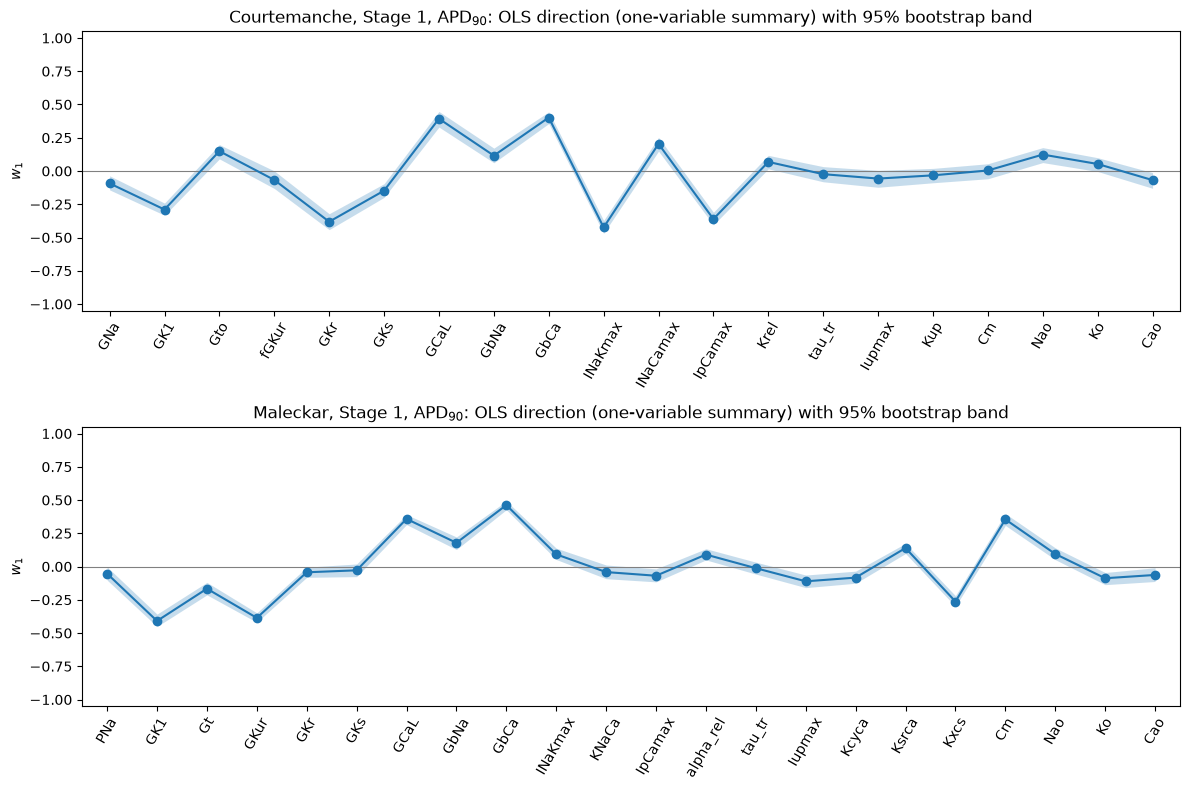

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
for ax, model in zip(axes, MODELS):
    ac.plotting.plot_eigenvectors(ols[model], indices=[0], interval='percentile', ax=[ax],
                                  labels=NAMES[model, 1])
    ax.set_title(f'{TITLE[model]}, Stage 1, APD$_{{90}}$: OLS direction (one-variable summary) with 95% bootstrap band')
    ax.tick_params(axis='x', labelrotation=60)
fig.tight_layout()
plt.close(fig)
for model in MODELS:
    w = ols[model].W[:, 0]
    band = ac.bootstrap_interval(ols[model].bootstrap_eigenvectors[:, :, 0])
    o = np.argsort(-np.abs(w))
    print(f'{TITLE[model]:12s} w1 (APD90 increases along w1): ' + ', '.join(f'{NAMES[model, 1][j]} {w[j]:+.3f}' for j in o[:7]))
    print(f'{"":12s} share of |w1|^2 in the top 5: {np.sum(w[o[:5]] ** 2):.3f}; components whose 95% band excludes 0: '
          f'{int(np.sum((band[0] > 0) | (band[1] < 0)))} of {len(w)}')
fig

In the Courtemanche model APD$_{90}$ increases along a direction that raises the inward currents ($G_{bCa}$ +0.402, $G_{CaL}$ +0.393, $I_{NaCa,max}$ +0.204) and lowers the outward and pump currents ($I_{NaK,max}$ −0.424, $G_{Kr}$ −0.381, $I_{pCa,max}$ −0.361, $G_{K1}$ −0.290); the top five carry 0.772 of $\lVert\mathbf w_1\rVert^2$, and 14 of 20 bootstrap bands exclude 0. In the Maleckar model the leading weights are $G_{bCa}$ +0.462, $G_{K1}$ −0.409, $G_{Kur}$ −0.386, $G_{CaL}$ +0.358 and $C_m$ +0.355, then $K_{xcs}$ −0.263 (a sarcoplasmic-reticulum Ca²⁺-handling constant); the top five carry 0.784, and 19 of 22 bands exclude 0. The intracellular Ca²⁺-handling inputs (except $K_{xcs}$) and the extracellular concentrations have small weights in both models. This is the inward-lengthens, outward-shortens picture of the paper's Sec. 3.1, and it already shows the two models differ: $G_{Kr}$ and $I_{NaK,max}$ matter in Courtemanche, $G_{Kur}$ and $C_m$ in Maleckar.

**Sufficient summary plots,** with a cubic in $y_1$ (black).

Courtemanche y1 in [-1.44, 1.50]; APD90 142.0-482.9 ms; corr(y1, APD90) = 0.912; LOO R^2: cubic in y1 0.834, linear in all inputs 0.803
Maleckar     y1 in [-1.59, 1.42]; APD90 81.8-431.3 ms; corr(y1, APD90) = 0.928; LOO R^2: cubic in y1 0.920, linear in all inputs 0.835


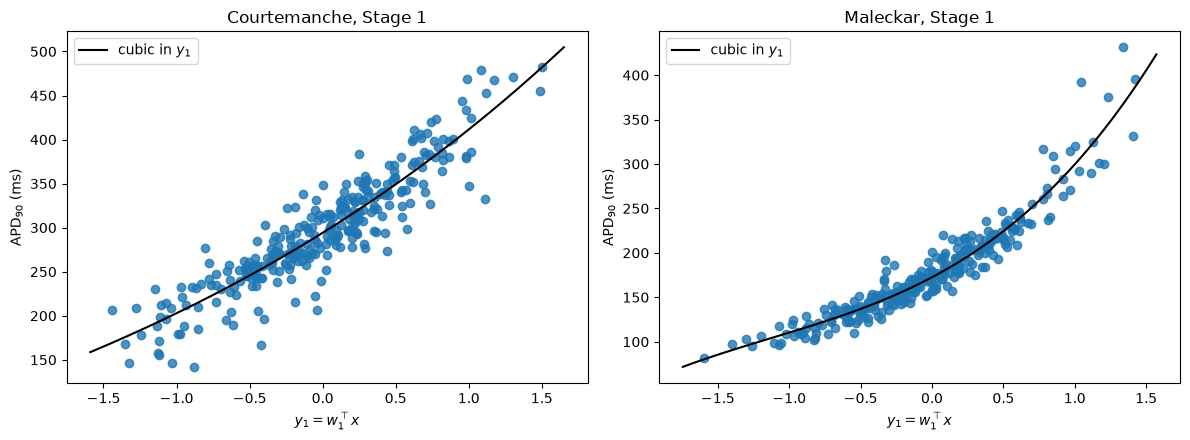

In [10]:
s1fit = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, model in zip(axes, MODELS):
    Xs, f = X[model, 1], F[model, 1][:, K90]
    ac.plotting.plot_sufficient_summary(ols[model], X=Xs, f=f, dims=1, qoi_label='APD$_{90}$ (ms)', ax=ax)
    s1fit[model] = ac.fit_surrogate(X=Xs, f=f, subspace=ols[model], kind='poly', degree=3)
    y = np.linspace(*ax.get_xlim(), 200)
    ax.plot(y, s1fit[model].evaluate(y[:, None]), 'k-', lw=1.5, label='cubic in $y_1$')
    ax.legend()
    ax.set_title(f'{TITLE[model]}, Stage 1')
fig.tight_layout()
plt.close(fig)
for model in MODELS:
    Xs, f = X[model, 1], F[model, 1][:, K90]
    y1 = space[model, 1].to_normalized(Xs) @ ols[model].W[:, 0]
    print(f'{TITLE[model]:12s} y1 in [{y1.min():.2f}, {y1.max():.2f}]; APD90 {f.min():.1f}-{f.max():.1f} ms; corr(y1, APD90) = {np.corrcoef(y1, f)[0, 1]:.3f}; '
          f'LOO R^2: cubic in y1 {s1fit[model].loo_r_squared:.3f}, linear in all inputs {loo(Xs, f, space[model, 1], 1):.3f}')
fig

APD$_{90}$ follows the single active variable in both models: $\mathrm{corr}(y_1, \mathrm{APD}_{90})$ = 0.912 (Courtemanche) and 0.928 (Maleckar). The Maleckar trend is convex, from about 80 ms to 430 ms, and a cubic in $y_1$ has LOO $R^2$ = 0.920, more than the 22-input linear model (0.835). The Courtemanche trend is nearly linear with more scatter (cubic in $y_1$: 0.834; 20-input linear model: 0.803), and the partial quadratic above, with curvature in the Stage 2 inputs, reaches LOO $R^2$ = 0.879: the scatter is partly a second direction or interactions, which the paper also found largest for APD$_{50}$ and APD$_{90}$ (Fig. 4). Stage 2 measures this directly.

### Results, Stage 2: APD$_{90}$ over the reduced inputs and DI

QPHD on the 200 Courtemanche runs ($m$ = 10) and the 195 Maleckar runs ($m$ = 8), with 500 bootstrap replicates. The dimension is chosen after the surrogates below, by the rule stated above.

In [11]:
qp = {}
msgs = set()
t0 = time.perf_counter()
for model in MODELS:
    sp, Xs, f = space[model, 2], X[model, 2], F[model, 2][:, K90]
    s, w = capture(ac.active_subspace, space=sp, X=Xs, f=f, estimator='qphd', nboot=NBOOT, bootstrap_vectors=2, rng=SEED)
    msgs.update(w)
    qp[model] = ac.orient(s, by='covariance', X=Xs, f=f, columns=2)
print(f'QPHD, {NBOOT} bootstrap replicates each: {time.perf_counter() - t0:.1f} s')
for m_ in sorted(msgs):
    print(m_[:200])
for model in MODELS:
    lam = qp[model].eigenvalues
    print(f'{TITLE[model]:12s} eigenvalues ' + np.array2string(lam, precision=3)
          + f'\n{"":12s} lambda_1/lambda_2 = {lam[0] / lam[1]:.1f}, lambda_2/lambda_3 = {lam[1] / lam[2]:.2f}; '
          f'(library default rule, linear eigenvalue gap, not used: n = {qp[model].n})')

QPHD, 500 bootstrap replicates each: 1.2 s
Courtemanche eigenvalues [1.781e+04 2.375e+03 9.992e+02 4.548e+02 2.058e+02 1.014e+02 7.409e+01
 5.641e+01 1.658e+01 1.875e+00]
             lambda_1/lambda_2 = 7.5, lambda_2/lambda_3 = 2.38; (library default rule, linear eigenvalue gap, not used: n = 1)
Maleckar     eigenvalues [5.996e+03 1.921e+02 1.093e+02 4.323e+01 1.958e+01 9.617e+00 3.308e+00
 1.339e+00]
             lambda_1/lambda_2 = 31.2, lambda_2/lambda_3 = 1.76; (library default rule, linear eigenvalue gap, not used: n = 1)


The first gap is moderate for Courtemanche, $\lambda_1/\lambda_2$ = 7.5 ($\lambda_2/\lambda_3$ = 2.38), and large for Maleckar, 31.2 ($\lambda_2/\lambda_3$ = 1.76). The library's default linear-gap rule returns $n = 1$ for both, but for Courtemanche that only says $\lambda_1 - \lambda_2 > \lambda_2 - \lambda_3$; whether $y_2$ matters is decided by the surrogates below. Two warnings appear (validity of QPHD on a cube; poorly aligned bootstrap replicates of $\mathbf w_2$).

Courtemanche 95% intervals: lambda_1 [1.617e+04, 2.001e+04], lambda_2 [2017, 3683], lambda_3 [791.1, 2030]; lambda_1/lambda_2 [5.0, 8.8], lambda_2/lambda_3 [1.22, 3.75]
Maleckar     95% intervals: lambda_1 [5691, 6262], lambda_2 [132.2, 287.9], lambda_3 [72.86, 194.8]; lambda_1/lambda_2 [21.0, 44.4], lambda_2/lambda_3 [1.07, 2.86]


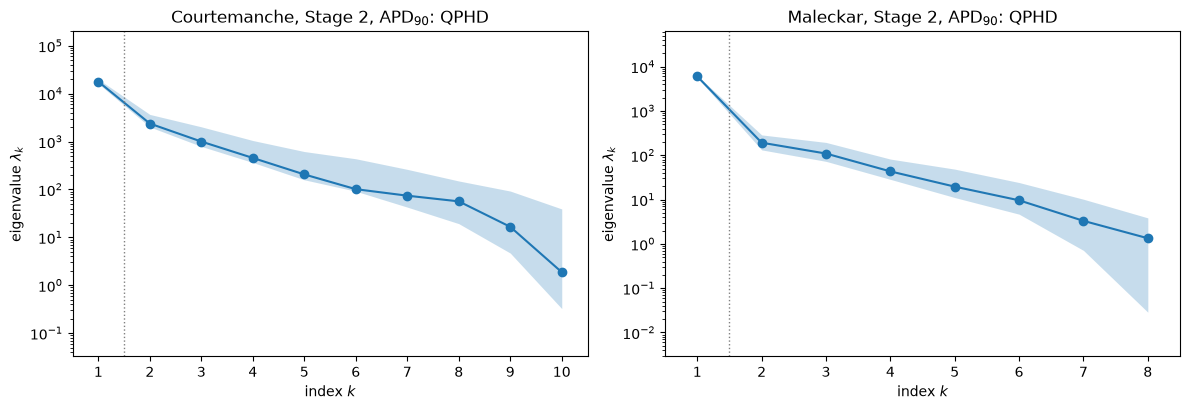

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, model in zip(axes, MODELS):
    ac.plotting.plot_eigenvalues(qp[model], interval='percentile', ax=ax)
    ax.set_title(f'{TITLE[model]}, Stage 2, APD$_{{90}}$: QPHD')
fig.tight_layout()
plt.close(fig)
for model in MODELS:
    B = qp[model].bootstrap_eigenvalues
    band = ac.bootstrap_interval(B)
    r12, r23 = B[:, 0] / B[:, 1], B[:, 1] / B[:, 2]
    print(f'{TITLE[model]:12s} 95% intervals: lambda_1 [{band[0, 0]:.4g}, {band[1, 0]:.4g}], lambda_2 [{band[0, 1]:.4g}, {band[1, 1]:.4g}], '
          f'lambda_3 [{band[0, 2]:.4g}, {band[1, 2]:.4g}]; lambda_1/lambda_2 [{np.percentile(r12, 2.5):.1f}, {np.percentile(r12, 97.5):.1f}], '
          f'lambda_2/lambda_3 [{np.percentile(r23, 2.5):.2f}, {np.percentile(r23, 97.5):.2f}]')
fig

The bootstrap intervals of $\lambda_1/\lambda_2$ are [5.0, 8.8] (Courtemanche) and [21.0, 44.4] (Maleckar); those of $\lambda_2/\lambda_3$, [1.22, 3.75] and [1.07, 2.86], reach close to 1, so beyond the first direction the spectra have no clear gap.

Courtemanche bootstrap mean subspace distance k = 1..4: [0.071 0.284 0.425 0.573]
Maleckar     bootstrap mean subspace distance k = 1..4: [0.027 0.254 0.314 0.465]


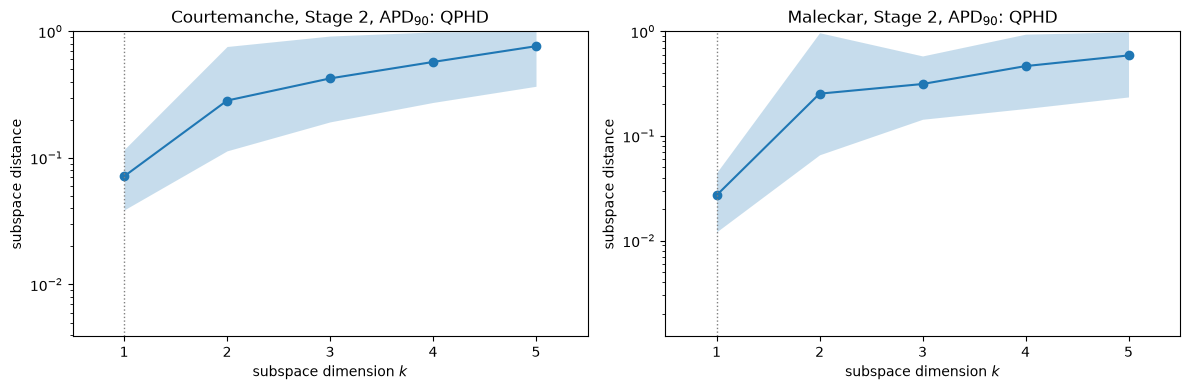

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, model in zip(axes, MODELS):
    ac.plotting.plot_subspace_errors(qp[model], interval='percentile', k_max=5, ax=ax)
    ax.set_title(f'{TITLE[model]}, Stage 2, APD$_{{90}}$: QPHD')
fig.tight_layout()
plt.close(fig)
for model in MODELS:
    print(f'{TITLE[model]:12s} bootstrap mean subspace distance k = 1..4: '
          + np.array2string(qp[model].bootstrap_distances.mean(axis=0)[:4], precision=3))
fig

The mean subspace distance is 0.071 (Courtemanche) and 0.027 (Maleckar) for $k = 1$, and 0.284 and 0.254 for $k = 2$: the first direction is well determined, the second less so.

Courtemanche w1: GK1 -0.382, Gto +0.018, fGKur +0.024, GKr -0.348, GCaL +0.355, GbCa +0.514, INaKmax -0.400, INaCamax +0.204, IpCamax -0.331, DI +0.176
             w2: GK1 -0.152, Gto +0.351, fGKur +0.389, GKr -0.375, GCaL -0.631, GbCa +0.144, INaKmax +0.044, INaCamax +0.108, IpCamax -0.015, DI -0.358
Maleckar     w1: GK1 -0.465, Gt -0.194, GKur -0.436, GCaL +0.410, GbCa +0.455, INaKmax +0.130, Cm +0.398, DI +0.082
             w2: GK1 -0.460, Gt -0.005, GKur +0.682, GCaL -0.394, GbCa +0.344, INaKmax +0.137, Cm +0.176, DI -0.003


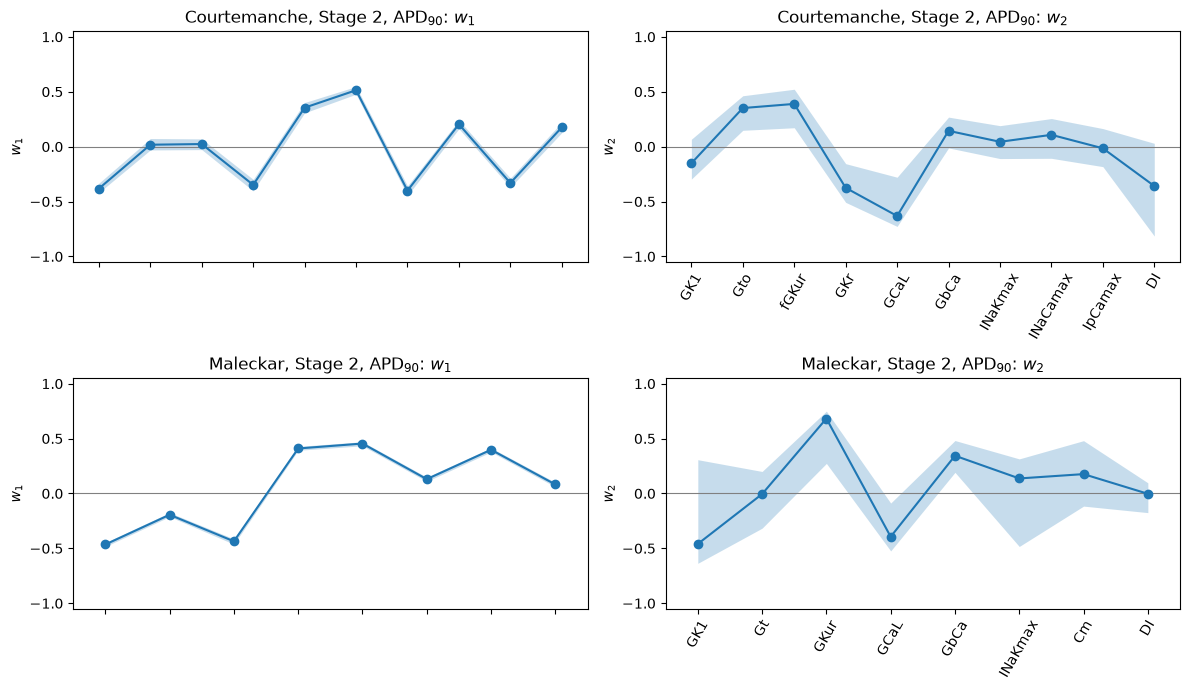

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for row, model in enumerate(MODELS):
    ac.plotting.plot_eigenvectors(qp[model], indices=[0, 1], interval='percentile', ax=list(axes[row]),
                                  labels=NAMES[model, 2])
    for j, ax in enumerate(axes[row]):
        ax.set_title(f'{TITLE[model]}, Stage 2, APD$_{{90}}$: $w_{j + 1}$')
        ax.tick_params(axis='x', labelrotation=60)
fig.tight_layout()
plt.close(fig)
for model in MODELS:
    w1, w2 = qp[model].W[:, 0], qp[model].W[:, 1]
    print(f'{TITLE[model]:12s} w1: ' + ', '.join(f'{n} {v:+.3f}' for n, v in zip(NAMES[model, 2], w1)))
    print(f'{"":12s} w2: ' + ', '.join(f'{n} {v:+.3f}' for n, v in zip(NAMES[model, 2], w2)))
fig

Courtemanche: $\mathbf w_1$ is led by $G_{bCa}$ (+0.514), $I_{NaK,max}$ (−0.400), $G_{K1}$ (−0.382), $G_{CaL}$ (+0.355), $G_{Kr}$ (−0.348) and $I_{pCa,max}$ (−0.331), with DI at +0.176 (longer diastolic interval, longer APD: restitution); $G_{to}$ and $f_{GKur}$ have weights of +0.018 and +0.024. The second direction is mostly $G_{CaL}$ (−0.631), with $f_{GKur}$ (+0.389), $G_{Kr}$ (−0.375), DI (−0.358) and $G_{to}$ (+0.351): the plateau currents. Maleckar: $\mathbf w_1$ is $G_{K1}$ (−0.465), $G_{bCa}$ (+0.455), $G_{Kur}$ (−0.436), $G_{CaL}$ (+0.410) and $C_m$ (+0.398); DI has only +0.082. So $G_{Kur}$ shortens the Maleckar APD$_{90}$ strongly while the Courtemanche multiplier $f_{GKur}$ has almost no linear effect (+0.024 here, −0.067 in Stage 1). The paper found the same contrast, a large negative main effect of $G_{Kur}$ in Maleckar and a small, non-linear, opposite one in Courtemanche, and confirmed it by simulation (Figs. 9 and 10); a linear direction cannot resolve the sign of so small and curved an effect.

Courtemanche y1 in [-1.61, 1.26], y2 in [-1.52, 1.47]; APD90 126.0-509.3 ms; corr(y1, APD90) = 0.901
Maleckar     y1 in [-1.53, 1.66], y2 in [-1.57, 1.55]; APD90 75.0-327.8 ms; corr(y1, APD90) = 0.963


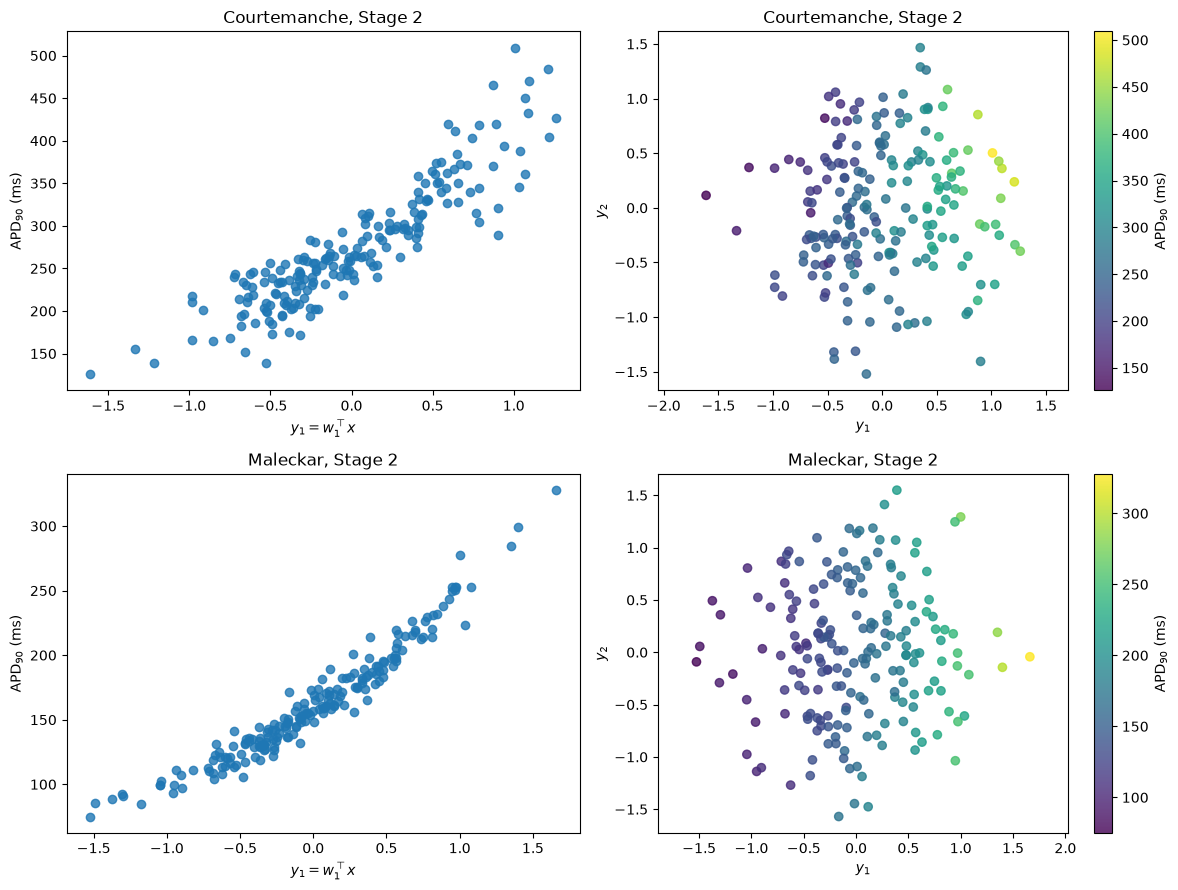

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for row, model in enumerate(MODELS):
    Xs, f = X[model, 2], F[model, 2][:, K90]
    ac.plotting.plot_sufficient_summary(qp[model], X=Xs, f=f, dims=1, qoi_label='APD$_{90}$ (ms)', ax=axes[row, 0])
    ac.plotting.plot_sufficient_summary(qp[model], X=Xs, f=f, dims=2, qoi_label='APD$_{90}$ (ms)', ax=axes[row, 1])
    axes[row, 0].set_title(f'{TITLE[model]}, Stage 2')
    axes[row, 1].set_title(f'{TITLE[model]}, Stage 2')
fig.tight_layout()
plt.close(fig)
for model in MODELS:
    Xs, f = X[model, 2], F[model, 2][:, K90]
    y = space[model, 2].to_normalized(Xs) @ qp[model].W[:, :2]
    print(f'{TITLE[model]:12s} y1 in [{y[:, 0].min():.2f}, {y[:, 0].max():.2f}], y2 in [{y[:, 1].min():.2f}, {y[:, 1].max():.2f}]; '
          f'APD90 {f.min():.1f}-{f.max():.1f} ms; corr(y1, APD90) = {np.corrcoef(y[:, 0], f)[0, 1]:.3f}')
fig

The Maleckar APD$_{90}$ lies close to one convex curve in $y_1$ ($\mathrm{corr}(y_1, \mathrm{APD}_{90})$ = 0.963), and in the two-variable plot its colour changes almost only along $y_1$. The Courtemanche plot has a wider band ($\mathrm{corr}$ = 0.901), and the colour also changes along $y_2$ at large $y_1$. The surrogates below put numbers on this.

In [16]:
def cubic_loo(Xs, f, sub, n):
    """LOO R^2 of a cubic polynomial in the first n active variables of sub."""
    return ac.fit_surrogate(X=Xs, f=f, subspace=ac.with_dimension(sub, n), kind='poly', degree=3).loo_r_squared

def choose_n(r, tol=TOL):
    """Dimension rule: the smallest n whose LOO R^2 (r[n-1], n = 1, 2, 3) is within tol of the best."""
    return 1 + next(i for i, v in enumerate(r) if v >= max(r) - tol)

sur2, n_apd90 = {}, {}
for model in MODELS:
    Xs, f = X[model, 2], F[model, 2][:, K90]
    r = {f'{n}-D cubic': cubic_loo(Xs, f, qp[model], n) for n in (1, 2, 3)}
    n_apd90[model] = choose_n(list(r.values()))
    r[f'{Xs.shape[1]}-D quadratic'] = loo(Xs, f, space[model, 2], 2)
    sur2[model] = r
    print(f'{TITLE[model]:12s} APD90 LOO R^2: ' + ', '.join(f'{k} {v:.3f}' for k, v in r.items())
          + f'  ->  chosen n = {n_apd90[model]} (smallest n <= 3 within TOL = {TOL} of the best cubic)')

Courtemanche APD90 LOO R^2: 1-D cubic 0.820, 2-D cubic 0.915, 3-D cubic 0.937, 10-D quadratic 0.919  ->  chosen n = 2 (smallest n <= 3 within TOL = 0.03 of the best cubic)
Maleckar     APD90 LOO R^2: 1-D cubic 0.959, 2-D cubic 0.977, 3-D cubic 0.982, 8-D quadratic 0.983  ->  chosen n = 1 (smallest n <= 3 within TOL = 0.03 of the best cubic)


For Maleckar a cubic in one active variable reaches LOO $R^2$ = 0.959, and two or three variables add little (0.977, 0.982; the full 8-input quadratic gives 0.983), so the rule chooses $n = 1$. For Courtemanche one variable gives 0.820, two give 0.915 and three 0.937 (full 10-input quadratic 0.919); 0.915 is within 0.03 of 0.937, so the rule chooses $n = 2$: the Courtemanche APD$_{90}$ is a two-dimensional function of these inputs, not a one-dimensional one.

#### Stage 1 and Stage 2 directions

Stage 2 fixes inputs that Stage 1 found unimportant. If that was right, the Stage 1 direction should put most of its weight on the Stage 2 inputs and point the same way there.

In [17]:
for model in MODELS:
    n1, n2 = NAMES[model, 1], NAMES[model, 2][:-1]
    idx = [n1.index(n) for n in n2]
    w_s1 = ols[model].W[:, 0]
    share = np.sum(w_s1[idx] ** 2)
    rest = [j for j in range(len(n1)) if j not in idx]
    rest = sorted(rest, key=lambda j: -w_s1[j] ** 2)[:3]
    print(f'{TITLE[model]:12s} largest Stage 1 weights^2 on inputs fixed in Stage 2: '
          + ', '.join(f'{n1[j]} {w_s1[j] ** 2:.3f}' for j in rest))
    a = w_s1[idx] / np.linalg.norm(w_s1[idx])
    b = qp[model].W[:-1, 0] / np.linalg.norm(qp[model].W[:-1, 0])
    print(f'{TITLE[model]:12s} share of the Stage 1 OLS |w1|^2 on the Stage 2 inputs: {share:.3f}; '
          f'DI weight in Stage 2 w1: {qp[model].W[-1, 0]:+.3f}; cosine between the two directions restricted to the shared inputs: {a @ b:.3f}')

Courtemanche largest Stage 1 weights^2 on inputs fixed in Stage 2: GKs 0.022, Nao 0.015, GbNa 0.013
Courtemanche share of the Stage 1 OLS |w1|^2 on the Stage 2 inputs: 0.924; DI weight in Stage 2 w1: +0.176; cosine between the two directions restricted to the shared inputs: 0.974
Maleckar     largest Stage 1 weights^2 on inputs fixed in Stage 2: Kxcs 0.069, GbNa 0.032, Ksrca 0.019
Maleckar     share of the Stage 1 OLS |w1|^2 on the Stage 2 inputs: 0.820; DI weight in Stage 2 w1: +0.082; cosine between the two directions restricted to the shared inputs: 0.998


The Stage 2 inputs carry 0.924 (Courtemanche) and 0.820 (Maleckar) of the Stage 1 $\lVert\mathbf w_1\rVert^2$, and on those inputs the two directions agree, with cosines 0.974 and 0.998, although the protocols differ (steady pacing versus an S2 beat). For Maleckar the largest Stage 1 weights on inputs that Stage 2 fixed are $K_{xcs}$ (0.069 of $\lVert\mathbf w_1\rVert^2$) and $G_{bNa}$ (0.032).

### All eleven biomarkers

Two tables per model. **Stage 1** (one-variable summaries only): LOO $R^2$ of the linear model in all inputs, of a cubic in the OLS active variable $y_1$ (the one-variable summary) and of the partial quadratic (curvature in the Stage 2 inputs), and the three largest components of the OLS direction. **Stage 2** (QPHD, 500 bootstrap replicates): $\lambda_1/\lambda_2$ and $\lambda_2/\lambda_3$ with 95 % bootstrap intervals, the LOO $R^2$ of a cubic in $n$ = 1, 2, 3 active variables and of the full quadratic, the chosen $n$ (smallest $n \le 3$ within `TOL` = 0.03 of the best cubic), the weight of DI in $\mathbf w_1$, and the three largest components of $\mathbf w_1$ (oriented so that the biomarker increases along it).

In [18]:
def top(names, w, k=3):
    o = np.argsort(-np.abs(w))[:k]
    return ' '.join(f'{names[j]}{w[j]:+.2f}' for j in o)

tab = {}
t0 = time.perf_counter()
for model in MODELS:
    Z1 = space[model, 1].to_normalized(X[model, 1])
    S = [NAMES[model, 1].index(n) for n in NAMES[model, 2][:-1]]
    for k, q in enumerate(cd.QOI_NAMES):
        sp1, X1, f1 = space[model, 1], X[model, 1], F[model, 1][:, k]
        so, _ = capture(ac.active_subspace, space=sp1, X=X1, f=f1, estimator='ols', n=1)
        A, _, _ = partial_quadratic(Z1, f1, S)
        sp2, X2, f2 = space[model, 2], X[model, 2], F[model, 2][:, k]
        sq, _ = capture(ac.active_subspace, space=sp2, X=X2, f=f2, estimator='qphd', nboot=NBOOT, rng=SEED)
        sq = ac.orient(sq, by='covariance', X=X2, f=f2, columns=1)
        lam, B = sq.eigenvalues, sq.bootstrap_eigenvalues
        r = [cubic_loo(X2, f2, sq, n) for n in (1, 2, 3)]
        tab[model, q] = dict(lin=loo(X1, f1, sp1, 1), cub1=ac.fit_surrogate(X=X1, f=f1, subspace=so, kind='poly', degree=3).loo_r_squared,
                             pq=loo_lstsq(A, f1), w_s1=so.W[:, 0], r12=lam[0] / lam[1], r23=lam[1] / lam[2],
                             r12_int=np.percentile(B[:, 0] / B[:, 1], [2.5, 97.5]), r23_int=np.percentile(B[:, 1] / B[:, 2], [2.5, 97.5]),
                             r2=r, quad2=loo(X2, f2, sp2, 2), n=choose_n(r), n_lingap=sq.n, w_s2=sq.W[:, 0])
for model in MODELS:
    print(f'{TITLE[model]} model, Stage 1 (m = {len(NAMES[model, 1])}): one-variable summaries; the dimension is not determined.')
    print(f"{'QoI':9s}{'lin R2':>8s}{'cubic(y1)':>10s}{'part.quad':>10s}   top OLS components (w1)")
    for q in cd.QOI_NAMES:
        t = tab[model, q]
        print(f"{q:9s}{t['lin']:8.3f}{t['cub1']:10.3f}{t['pq']:10.3f}   {top(NAMES[model, 1], t['w_s1'])}")
    print(f'{TITLE[model]} model, Stage 2 (m = {len(NAMES[model, 2])}): QPHD; LOO R^2 of a cubic in n active variables; n by the TOL rule.')
    print(f"{'QoI':9s}{'l1/l2':>6s} {'95% int.':<13s}{'l2/l3':>6s} {'95% int.':<12s}{'n=1':>7s}{'n=2':>7s}{'n=3':>7s}{'quad':>7s}{'n':>3s}{'DI w1':>7s}   top components (w1)")
    for q in cd.QOI_NAMES:
        t = tab[model, q]
        a, b = t['r12_int'], t['r23_int']
        print(f"{q:9s}{t['r12']:6.1f} [{a[0]:5.1f},{a[1]:5.1f}]{t['r23']:6.2f} [{b[0]:4.2f},{b[1]:4.2f}]"
              + ''.join(f'{v:7.3f}' for v in t['r2']) + f"{t['quad2']:7.3f}{t['n']:3d}{t['w_s2'][-1]:+7.2f}   {top(NAMES[model, 2], t['w_s2'])}")
    print()
ns = np.array([tab[key]['n'] for key in tab])
print(f'Stage 2, chosen n over the 22 cases (TOL = {TOL}): n = 1: {np.sum(ns == 1)}, n = 2: {np.sum(ns == 2)}, n = 3: {np.sum(ns == 3)}')
print('   n = 1 for: ' + ', '.join(f'{TITLE[mo][0]} {q}' for (mo, q), t in tab.items() if t['n'] == 1))
for tol in (0.02, 0.05):
    nt = np.array([choose_n(t['r2'], tol) for t in tab.values()])
    print(f'   with TOL = {tol}: n = 1: {np.sum(nt == 1)}, n = 2: {np.sum(nt == 2)}, n = 3: {np.sum(nt == 3)}')
print(f'   library default rule (linear eigenvalue gap), for reference: n = 1 in {sum(t["n_lingap"] == 1 for t in tab.values())} of 22')
print(f'   cases where a second active variable raises the cubic LOO R^2 by more than 0.05: '
      f'{sum(t["r2"][1] - t["r2"][0] > 0.05 for t in tab.values())} of 22')
print(f'({time.perf_counter() - t0:.1f} s)')

Courtemanche model, Stage 1 (m = 20): one-variable summaries; the dimension is not determined.
QoI        lin R2 cubic(y1) part.quad   top OLS components (w1)
dVdt_max    0.946     0.954     0.948   GNa+0.97 Cm-0.14 GbCa-0.10
Vmax        0.944     0.951     0.936   GNa+0.94 Cm-0.32 Nao+0.07
V20         0.890     0.914     0.937   GCaL+0.70 fGKur-0.38 Gto-0.36
V40         0.838     0.873     0.884   GCaL+0.75 fGKur-0.48 Nao+0.26
V60         0.749     0.788     0.793   GCaL+0.67 fGKur-0.47 GbCa-0.29
V80         0.664     0.722     0.740   GCaL+0.48 GK1+0.40 INaCamax-0.37
APD50       0.743     0.800     0.811   GCaL+0.76 fGKur-0.36 GNa-0.31
APD90       0.803     0.834     0.879   INaKmax-0.42 GbCa+0.40 GCaL+0.39
RestVm      0.961     0.981     0.981   GbCa+0.62 Ko+0.53 INaKmax-0.30
Ca_min      0.929     0.959     0.952   GbCa+0.52 GCaL+0.48 INaCamax-0.41
Ca_max      0.845     0.959     0.875   GCaL+0.59 Kup-0.43 GbCa+0.36
Courtemanche model, Stage 2 (m = 10): QPHD; LOO R^2 of a cubic in n

By the stated rule (`TOL` = 0.03) the Stage 2 dimension is $n = 1$ in 7 of the 22 cases (Courtemanche resting potential; Maleckar $V_{20}$, $V_{80}$, APD$_{90}$, resting potential, $\mathrm{Ca}_{min}$, $\mathrm{Ca}_{max}$), $n = 2$ in 13, and $n = 3$ in 2 (Courtemanche $V_{20}$ and APD$_{50}$, where 3 means "at least 3"). The counts depend on the tolerance (4, 12 and 6 with 0.02; 12, 9 and 1 with 0.05), so the evidence is the LOO $R^2$ columns, not the counts. The library's linear-gap rule returns $n = 1$ in 22 of 22, yet a second active variable raises the cubic LOO $R^2$ by more than 0.05 in 9 of 22 cases. The clearest are the Courtemanche plateau voltages ($V_{40}$: 0.756 with one variable, 0.882 with two; $V_{60}$: 0.652, 0.848; $V_{80}$: 0.567, 0.822), where $\lambda_1/\lambda_2$ is only 3.4, 2.6 and 2.6, with intervals down to 2.1, 1.7 and 1.8, and $\lambda_2/\lambda_3$ (5.07, 4.33, 3.24) is larger than $\lambda_1/\lambda_2$: the larger gap is after $\lambda_2$. This is the spike-and-dome shape, whose voltages depend on the balance of $I_{CaL}$, $I_{to}$ and $I_{Kur}$ and, after an S2 beat, on DI. The upstroke also needs two variables in both models (Courtemanche $dV_m/dt_{max}$ 0.877 and 0.959, Maleckar 0.871 and 0.963). For Maleckar a single variable gives LOO $R^2$ of 0.930 or more for every biomarker except the upstroke (0.871, 0.887), so where the rule picks $n = 2$ for Maleckar ($V_{40}$, $V_{60}$, APD$_{50}$) the second variable is a refinement (0.954 to 0.978, 0.950 to 0.982, 0.930 to 0.967). Some percentile intervals of $\lambda_2/\lambda_3$ do not contain the point estimate (Courtemanche $dV_m/dt_{max}$: 9.22 against [1.10, 8.59]); ratios of ordered bootstrap eigenvalues are biased when eigenvalues are close, so read those intervals as a sign of instability.

In Stage 1 the one-variable summary has LOO $R^2$ between 0.722 (Courtemanche $V_{80}$) and 0.983 (Maleckar resting potential), 0.910 or more for every Maleckar biomarker. The partial quadratic beats it for the Courtemanche early plateau and APD$_{90}$ ($V_{20}$ 0.937 against 0.914, APD$_{90}$ 0.879 against 0.834) and for the Maleckar voltages, and falls below it where the curvature lies in inputs outside the Stage 2 set (Courtemanche $\mathrm{Ca}_{max}$ 0.875 against 0.959; Maleckar APD$_{50}$, APD$_{90}$, $\mathrm{Ca}_{min}$, $\mathrm{Ca}_{max}$). Neither column fixes a dimension. In Stage 2 the diastolic interval leads $\mathbf w_1$ for five Courtemanche biomarkers ($dV_m/dt_{max}$, $V_{max}$, $V_{40}$, $V_{60}$, $V_{80}$), but for no Maleckar biomarker (its largest DI weights are +0.46 for $\mathrm{Ca}_{max}$ and +0.39 for $V_{max}$), consistent with the paper's finding that DI matters more in the Courtemanche model (p. 9). The upstroke biomarkers are led by the Na⁺ conductance and $C_m$ in Stage 1 ($G_{Na}$ +0.97 and $P_{Na}$ +0.81 for $dV_m/dt_{max}$), which Stage 2 fixed.

The OLS directions of all biomarkers side by side (components with magnitude ≥ 0.2 are printed), to compare with the paper's Fig. 3:

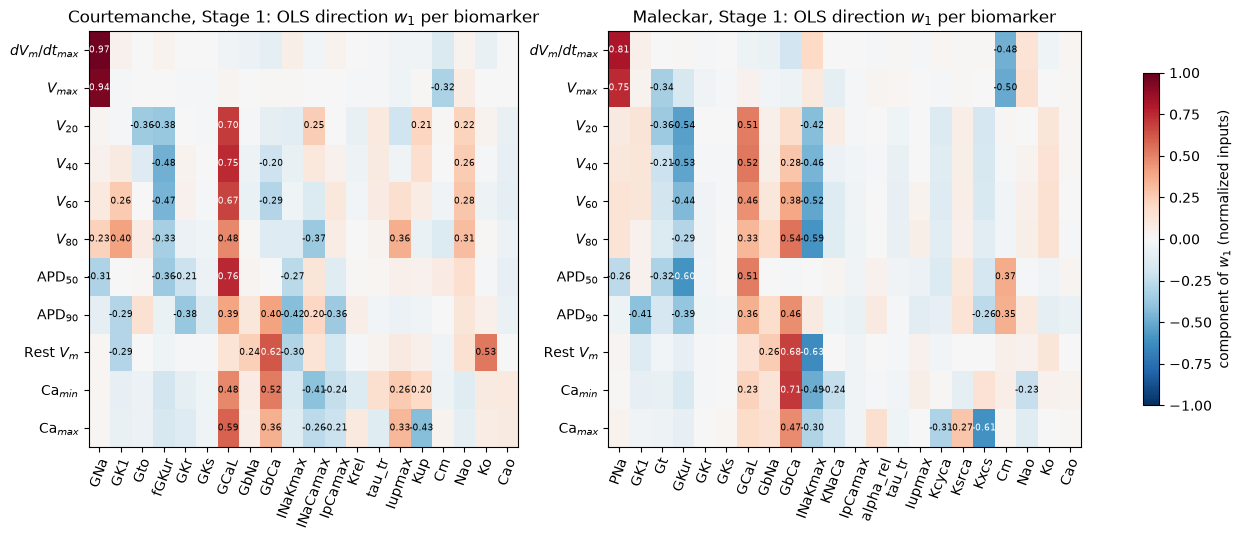

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.4), gridspec_kw={'width_ratios': [20, 22]})
for ax, model in zip(axes, MODELS):
    Wm = np.array([tab[model, q]['w_s1'] for q in cd.QOI_NAMES])
    im = ax.imshow(Wm, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
    ax.set_xticks(range(len(NAMES[model, 1])), NAMES[model, 1], rotation=70)
    ax.set_yticks(range(len(cd.QOI_NAMES)), cd.QOI_LABELS)
    for i in range(Wm.shape[0]):
        for j in range(Wm.shape[1]):
            if abs(Wm[i, j]) >= 0.2:
                ax.text(j, i, f'{Wm[i, j]:.2f}', ha="center", va="center", fontsize=6.5,
                        color='w' if abs(Wm[i, j]) > 0.6 else 'k')
    ax.set_title(f'{TITLE[model]}, Stage 1: OLS direction $w_1$ per biomarker')
fig.colorbar(im, ax=axes, shrink=0.8, label='component of $w_1$ (normalized inputs)')
plt.close(fig)
fig

The patterns match the paper's Fig. 3 in their main features: the Na⁺ conductance and $C_m$ for the upstroke, $G_{CaL}$ and $G_{Kur}$ (opposite signs) for the early plateau, $G_{bCa}$ and $I_{NaK,max}$ for the Maleckar late plateau and resting potential, $G_{bCa}$, $G_{CaL}$ and $I_{NaCa,max}$ for Courtemanche calcium, and $K_{xcs}$ for the Maleckar $\mathrm{Ca}_{max}$. The extracellular concentrations ($[\mathrm{Na}^+]_o$, $[\mathrm{K}^+]_o$) weigh less here than in Fig. 3; the next section shows why.

Sufficient summary plots of all 22 Stage 1 cases (OLS active variable, a one-variable summary; the title gives the LOO $R^2$ of a cubic in $y_1$):

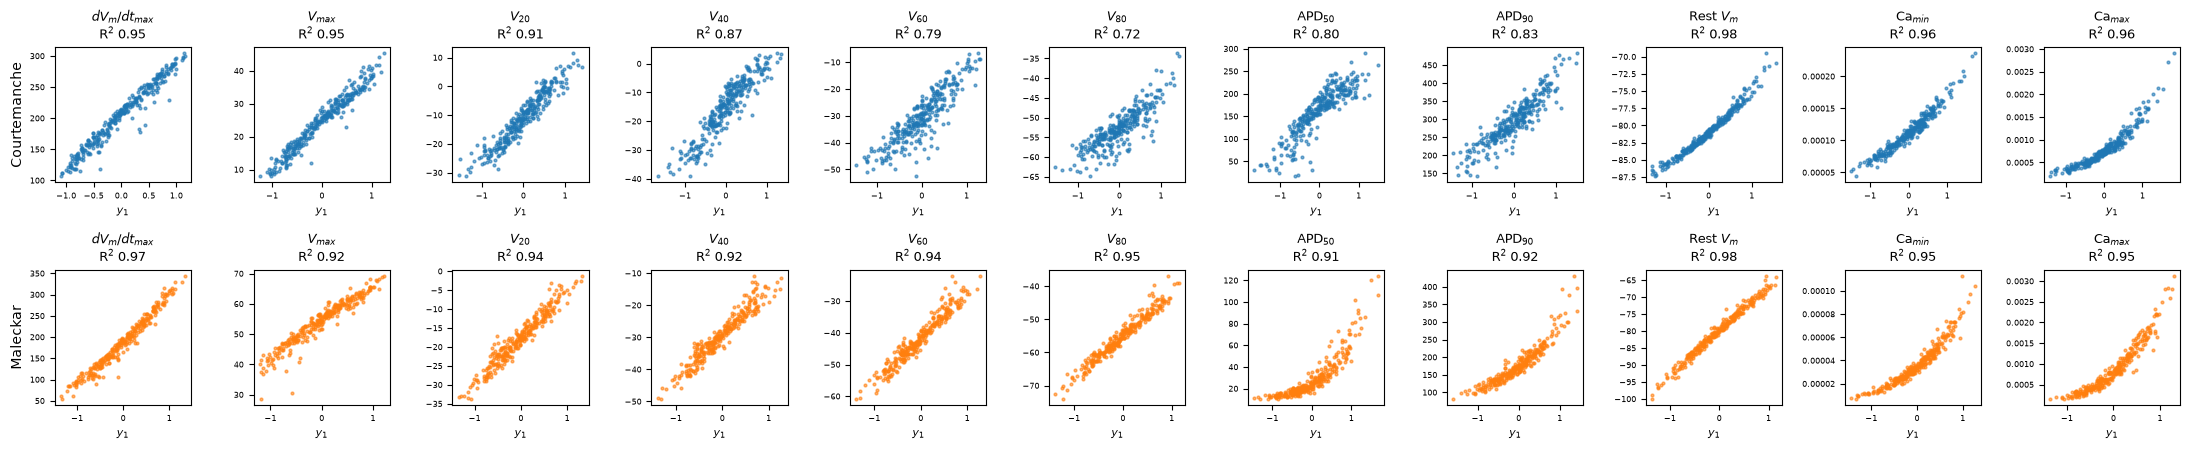

In [20]:
fig, axes = plt.subplots(2, 11, figsize=(22, 4.6))
for row, model in enumerate(MODELS):
    Z = space[model, 1].to_normalized(X[model, 1])
    for k, q in enumerate(cd.QOI_NAMES):
        ax = axes[row, k]
        ax.scatter(Z @ tab[model, q]['w_s1'], F[model, 1][:, k], s=4, alpha=0.6, color='C0' if row == 0 else 'C1')
        ax.set_title(f"{cd.QOI_LABELS[k]}\nR$^2$ {tab[model, q]['cub1']:.2f}", fontsize=9)
        ax.tick_params(labelsize=6)
        ax.set_xlabel('$y_1$', fontsize=8)
    axes[row, 0].set_ylabel(TITLE[model])
fig.tight_layout()
plt.close(fig)
fig

### Comparison with the paper's Sobol' indices

The paper's first-order and total Sobol' indices (Figs. 3, 4, 7, 8) come from Gaussian process emulators, computed by the Bayesian method of Oakley and O'Hagan [[6]](https://doi.org/10.1111/j.1467-9868.2004.05304.x) as in the authors' earlier study of a cardiac cell model [[7]](https://doi.org/10.1371/journal.pone.0130252), with the inputs **Gaussian** in normalized units $u\in[0,1]$, mean 0.5 and variance 0.02 for the ±50 % inputs, 0.04 for $G_{K1}$ and $C_m$, and 0.1 for the extracellular concentrations (Sec. 2.7, p. 6). This is not the uniform design distribution that the active subspace uses (variance 1/12 for every input in $u$). The paper's distribution doubles the relative variance of $G_{K1}$ and $C_m$ and multiplies that of the concentrations by 5, and it puts part of each input's mass outside the sampled range, where the emulator extrapolates: 11.38 % for each concentration (standard deviation 0.316) and 1.24 % for $G_{K1}$ and $C_m$ (standard deviation 0.200), against 0.04 % for the other inputs (printed below).

For a linear function and the uniform distribution, the first-order Sobol' indices are exactly the squared components $w_{1,i}^2$ of the OLS direction. To compare like with like we also compute, analytically, the Sobol' indices of the fitted linear model (Stage 1) or quadratic model (Stage 2) under the paper's Gaussian distribution, and for Stage 2 also under the uniform one. These are indices of a polynomial fit, so they share its error (LOO $R^2$ above), but they carry no Monte Carlo noise. The paper does not state the variance of DI in Stage 2; we use 0.02.

The paper's numbers below were read from the printed cells of Figs. 3, 4, 7 and 8 (rasterized at 200 dpi); Figs. 3 and 7 do not print first-order indices below 0.05, and Figs. 4 and 8 do not print total indices below 0.01.

In [21]:
# Signed first-order indices of Fig. 3 (Stage 1) of [1], as printed (entries below 0.05 are not printed).
FIG3 = {
 'courtemanche': {
  'dVdt_max': {'GNa': .83, 'Cm': -.08}, 'Vmax': {'GNa': .72, 'Cm': -.22},
  'V20': {'Gto': -.12, 'fGKur': -.11, 'GCaL': .36, 'Nao': .20}, 'V40': {'fGKur': -.20, 'GCaL': .42, 'Nao': .18},
  'V60': {'GK1': .10, 'fGKur': -.18, 'GCaL': .35, 'GbCa': -.06, 'Nao': .15},
  'V80': {'GK1': .20, 'fGKur': -.08, 'GCaL': .11, 'INaCamax': -.11, 'Iupmax': .07, 'Nao': .18},
  'APD50': {'GNa': -.10, 'fGKur': -.09, 'GKr': -.06, 'GCaL': .29, 'INaKmax': -.06, 'Nao': .13},
  'APD90': {'GK1': -.17, 'GKr': -.10, 'GCaL': .07, 'GbCa': .15, 'INaKmax': -.11, 'IpCamax': -.09, 'Nao': .07},
  'RestVm': {'GK1': -.08, 'GbCa': .17, 'Ko': .59},
  'Ca_min': {'GCaL': .24, 'GbCa': .19, 'INaCamax': -.14, 'Iupmax': .05, 'Nao': -.05},
  'Ca_max': {'GCaL': .35, 'GbCa': .09, 'INaCamax': -.07, 'Iupmax': .08, 'Kup': -.18}},
 'maleckar': {
  'dVdt_max': {'PNa': .49, 'Cm': -.34, 'Nao': .09}, 'Vmax': {'PNa': .37, 'Gt': -.10, 'Cm': -.34, 'Nao': .11},
  'V20': {'Gt': -.11, 'GKur': -.28, 'GCaL': .22, 'INaKmax': -.14, 'Ko': .05},
  'V40': {'GKur': -.25, 'GCaL': .23, 'GbCa': .08, 'INaKmax': -.18, 'Ko': .06},
  'V60': {'GKur': -.16, 'GCaL': .17, 'GbCa': .14, 'INaKmax': -.24, 'Ko': .07},
  'V80': {'GKur': -.08, 'GCaL': .09, 'GbCa': .26, 'INaKmax': -.31, 'Ko': .10},
  'APD50': {'GKur': -.18, 'GCaL': .24, 'Cm': .26},
  'APD90': {'GK1': -.24, 'GKur': -.09, 'GCaL': .08, 'GbCa': .12, 'Cm': .17},
  'RestVm': {'GbNa': .05, 'GbCa': .42, 'INaKmax': -.38, 'Ko': .07},
  'Ca_min': {'GbCa': .38, 'INaKmax': -.22, 'Nao': -.19},
  'Ca_max': {'GbCa': .21, 'INaKmax': -.09, 'Kcyca': -.08, 'Ksrca': .06, 'Kxcs': -.29, 'Nao': -.12}}}
# APD90 rows: total effects of Fig. 4 (Stage 1), first-order of Fig. 7 and total effects of Fig. 8 (Stage 2).
FIG4_APD90 = {
 'courtemanche': {'GNa': .01, 'GK1': .18, 'Gto': .04, 'fGKur': .01, 'GKr': .12, 'GKs': .01, 'GCaL': .10, 'GbNa': .02,
                  'GbCa': .17, 'INaKmax': .12, 'INaCamax': .04, 'IpCamax': .10, 'Iupmax': .02, 'Nao': .10, 'Ko': .04, 'Cao': .01},
 'maleckar': {'PNa': .06, 'GK1': .33, 'Gt': .07, 'GKur': .15, 'GKr': .06, 'GKs': .06, 'GCaL': .15, 'GbNa': .08, 'GbCa': .20,
              'INaKmax': .07, 'KNaCa': .06, 'IpCamax': .07, 'alpha_rel': .07, 'tau_tr': .06, 'Iupmax': .08, 'Kcyca': .06,
              'Ksrca': .07, 'Kxcs': .11, 'Cm': .23, 'Nao': .10, 'Ko': .09, 'Cao': .08}}
FIG7_APD90 = {'courtemanche': {'GK1': -.17, 'GKr': -.14, 'GCaL': .07, 'GbCa': .19, 'INaKmax': -.18, 'IpCamax': -.09, 'DI': .06},
              'maleckar': {'GK1': -.32, 'GKur': -.17, 'GCaL': .14, 'GbCa': .15, 'Cm': .14}}
FIG8_APD90 = {'courtemanche': {'GK1': .19, 'Gto': .02, 'fGKur': .02, 'GKr': .16, 'GCaL': .09, 'GbCa': .21, 'INaKmax': .19,
                               'INaCamax': .03, 'IpCamax': .10, 'DI': .07},
              'maleckar': {'GK1': .34, 'Gt': .04, 'GKur': .17, 'GCaL': .15, 'GbCa': .17, 'INaKmax': .01, 'Cm': .14}}

In [22]:
def unit_coords(model, stage):
    """Inputs on the paper's normalized scale u in [0, 1] (Sec. 2.5), centred: z = u - 1/2."""
    _, lo, hi = cd.bounds(model, stage)
    return (X[model, stage] - lo) / (hi - lo) - 0.5

def quad_indices(Z, f, var, degree):
    """First-order and total Sobol' indices of a least-squares polynomial (degree 1 or 2) in z, for
    independent inputs with variances var: Gaussian ('gauss', E z^4 = 3 var^2) or uniform on
    [-1/2, 1/2] ('unif', var = 1/12, E z^4 = 1/80). Exact for the fitted polynomial."""
    M, m = Z.shape
    cols = [np.ones(M)] + [Z[:, i] for i in range(m)]
    pairs = [(i, j) for i in range(m) for j in range(i, m)] if degree == 2 else []
    cols += [Z[:, i] * Z[:, j] for i, j in pairs]
    c, *_ = np.linalg.lstsq(np.column_stack(cols), f, rcond=None)
    b, a = c[1:m + 1], c[m + 1:]
    out = {}
    for kind in ('gauss', 'unif'):
        v = np.asarray(var, float) if kind == 'gauss' else np.full(m, 1 / 12)
        vsq = 2 * v ** 2 if kind == 'gauss' else np.full(m, 1 / 80 - 1 / 144)     # Var(z_i^2)
        first = b ** 2 * v
        inter = np.zeros(m)
        for (i, j), aij in zip(pairs, a):
            if i == j:
                first[i] += aij ** 2 * vsq[i]
            else:
                inter[i] += aij ** 2 * v[i] * v[j]
                inter[j] += aij ** 2 * v[i] * v[j]
        V = first.sum() + inter.sum() / 2
        out[kind] = (np.sign(b) * first / V, (first + inter) / V)
    return out

from math import erfc, sqrt
for v in (0.02, 0.04, 0.1):
    print(f'paper variance {v} in u: standard deviation {sqrt(v):.3f}; Gaussian mass outside [0, 1]: {100 * erfc(0.5 / sqrt(2 * v)):.2f} %')

sob = {}
for model in MODELS:
    for stage, deg in ((1, 1), (2, 2)):
        var = [r['paper_variance'] for r in cd.inputs(model, stage)]
        sob[model, stage] = quad_indices(unit_coords(model, stage), F[model, stage][:, K90], var, deg)

for model in MODELS:
    print(f'{TITLE[model]}, APD90, Stage 1. Paper: Fig. 3 (S, signed) and Fig. 4 (ST); notebook: w1^2 of the OLS direction '
          f'(uniform design), and S of the linear fit under the paper\'s Gaussian inputs (share of the linear model\'s variance).')
    print(f"{'input':10s}{'paper S':>9s}{'paper ST':>9s}{'w1^2 (OLS)':>11s}{'lin S, Gauss':>13s}")
    w = ols[model].W[:, 0]
    Sg = sob[model, 1]['gauss'][0]
    order = np.argsort(-np.maximum(np.abs(Sg), w ** 2))
    for j in order[:9]:
        n = NAMES[model, 1][j]
        ps = FIG3[model]['APD90'].get(n)
        print(f"{n:10s}{(f'{ps:+.2f}' if ps is not None else '<0.05'):>9s}{FIG4_APD90[model].get(n, 0):9.2f}{np.sign(w[j]) * w[j] ** 2:+11.3f}{Sg[j]:+13.3f}")
    print(f"{'sum |.|':10s}{sum(abs(v) for v in FIG3[model]['APD90'].values()):9.2f}{'':9s}{np.sum(w ** 2):11.3f}{np.sum(np.abs(Sg)):13.3f}")
    small = [n for j, n in enumerate(NAMES[model, 1]) if w[j] ** 2 < 0.01]
    print(f'inputs with w1^2 < 0.01: {len(small)} of {len(w)}; their paper ST (Fig. 4): '
          + ', '.join(f'{n} {FIG4_APD90[model].get(n, 0):.2f}' for n in small) + '\n')

paper variance 0.02 in u: standard deviation 0.141; Gaussian mass outside [0, 1]: 0.04 %
paper variance 0.04 in u: standard deviation 0.200; Gaussian mass outside [0, 1]: 1.24 %
paper variance 0.1 in u: standard deviation 0.316; Gaussian mass outside [0, 1]: 11.38 %
Courtemanche, APD90, Stage 1. Paper: Fig. 3 (S, signed) and Fig. 4 (ST); notebook: w1^2 of the OLS direction (uniform design), and S of the linear fit under the paper's Gaussian inputs (share of the linear model's variance).
input       paper S paper ST w1^2 (OLS) lin S, Gauss
INaKmax       -0.11     0.12     -0.180       -0.153
GbCa          +0.15     0.17     +0.162       +0.138
GCaL          +0.07     0.10     +0.154       +0.131
GKr           -0.10     0.12     -0.145       -0.124
GK1           -0.17     0.18     -0.084       -0.143
IpCamax       -0.09     0.10     -0.130       -0.111
Nao           +0.07     0.10     +0.015       +0.065
INaCamax      <0.05     0.04     +0.042       +0.035
Gto           <0.05     0.04   

**Stage 1, APD$_{90}$.** The notebook's linear indices are shares of the linear model's variance (they sum to 1), while the paper's printed indices sum to 0.76 (Courtemanche) and 0.70 (Maleckar) (the right-hand column of Fig. 3, which includes the unprinted values, gives 0.91 and 0.89); compare rankings and proportions. For Courtemanche the six largest inputs of both notebook columns ($I_{NaK,max}$, $G_{bCa}$, $G_{CaL}$, $G_{Kr}$, $I_{pCa,max}$, $G_{K1}$) are six of the seven inputs the paper prints, with the same signs. The paper ranks $G_{K1}$ first (−0.17); under the uniform design $G_{K1}$ is only sixth ($w_1^2$ = 0.084), but under the paper's Gaussian inputs, with its doubled variance, it rises to 0.143, next to $I_{NaK,max}$ (0.153), and $[\mathrm{Na}^+]_o$ rises from 0.015 to 0.065 (paper 0.07). For Maleckar the Gaussian linear indices are close to Fig. 3: $G_{K1}$ −0.243 (paper −0.24), $C_m$ +0.183 (+0.17), $G_{bCa}$ +0.155 (+0.12), $G_{Kur}$ −0.108 (−0.09), $G_{CaL}$ +0.093 (+0.08). Under the uniform design $G_{bCa}$ leads instead (0.214), and $G_{K1}$ (±25 %) and $C_m$ (±25 %) drop to 0.167 and 0.126. The Maleckar total indices of Fig. 4 are 0.06 or more for every input, which is where the paper's large interaction sum for this row (1.41) comes from. Twelve of the 22 inputs have $w_1^2 < 0.01$ here, yet Fig. 4 gives each of them a total index of 0.06–0.10. A cubic in $y_1$, to which these inputs contribute almost nothing, explains LOO $R^2$ = 0.920 and leaves about 0.08 of the variance, so such totals would need that remainder to be an interaction involving all twelve inputs at once. We think an emulator artefact more likely (the paper itself mentions "a more problematic emulator fit" as a possible cause of an unexpected Maleckar result, p. 17), but the runs cannot settle it.

In [23]:
for model in MODELS:
    print(f'{TITLE[model]}, APD90, Stage 2. Paper: Fig. 7 (S) and Fig. 8 (ST); notebook: Sobol\' indices of the least-squares '
          f'quadratic (LOO R^2 {sur2[model][f"{X[model, 2].shape[1]}-D quadratic"]:.3f}), under the paper\'s Gaussian inputs and under the uniform design; w1^2 of QPHD.')
    print(f"{'input':10s}{'paper S':>9s}{'paper ST':>9s}{'S Gauss':>9s}{'ST Gauss':>9s}{'S unif':>8s}{'ST unif':>8s}{'w1^2':>7s}")
    (Sg, STg), (Su, STu) = sob[model, 2]['gauss'], sob[model, 2]['unif']
    w = qp[model].W[:, 0]
    for j, n in enumerate(NAMES[model, 2]):
        ps = FIG7_APD90[model].get(n)
        print(f"{n:10s}{(f'{ps:+.2f}' if ps is not None else '<0.05'):>9s}{FIG8_APD90[model].get(n, 0):9.2f}"
              f"{Sg[j]:+9.3f}{STg[j]:9.3f}{Su[j]:+8.3f}{STu[j]:8.3f}{w[j] ** 2:7.3f}")
    print(f"{'sum':10s}{sum(abs(v) for v in FIG7_APD90[model].values()):9.2f}{'':9s}{np.sum(np.abs(Sg)):9.3f}{'':9s}{np.sum(np.abs(Su)):8.3f}")
    print(f"{'sum ST-|S|':10s}{sum(FIG8_APD90[model].values()) - sum(abs(v) for v in FIG7_APD90[model].values()):9.2f} (printed values; Fig. 8 prints "
          f"{ {'courtemanche': 0.14, 'maleckar': 0.06}[model]:.2f})   quadratic, Gaussian: {np.sum(STg - np.abs(Sg)):.3f}; uniform: {np.sum(STu - np.abs(Su)):.3f}\n")

Courtemanche, APD90, Stage 2. Paper: Fig. 7 (S) and Fig. 8 (ST); notebook: Sobol' indices of the least-squares quadratic (LOO R^2 0.919), under the paper's Gaussian inputs and under the uniform design; w1^2 of QPHD.
input       paper S paper ST  S Gauss ST Gauss  S unif ST unif   w1^2
GK1           -0.17     0.19   -0.229    0.241  -0.116   0.143  0.146
Gto           <0.05     0.02   +0.000    0.005  +0.000   0.017  0.000
fGKur         <0.05     0.02   -0.000    0.007  -0.001   0.026  0.001
GKr           -0.14     0.16   -0.119    0.126  -0.122   0.152  0.121
GCaL          +0.07     0.09   +0.118    0.127  +0.123   0.159  0.126
GbCa          +0.19     0.21   +0.201    0.213  +0.207   0.251  0.264
INaKmax       -0.18     0.19   -0.128    0.136  -0.131   0.159  0.160
INaCamax      <0.05     0.03   +0.039    0.041  +0.040   0.050  0.042
IpCamax       -0.09     0.10   -0.090    0.096  -0.092   0.113  0.110
DI            +0.06     0.07   +0.039    0.044  +0.043   0.058  0.031
sum           

**Stage 2, APD$_{90}$.** Here the quadratic fits are good (LOO $R^2$ 0.919 and 0.983), and their Gaussian indices are close to Fig. 7 for most inputs. Courtemanche: $G_{bCa}$ +0.201 (paper +0.19), $G_{Kr}$ −0.119 (−0.14), $I_{pCa,max}$ −0.090 (−0.09), $I_{NaK,max}$ −0.128 (−0.18), $G_{K1}$ −0.229 (−0.17), $G_{CaL}$ +0.118 (+0.07), DI +0.039 (+0.06), and $G_{to}$ and $f_{GKur}$ below 0.05 in both. Maleckar: $G_{K1}$ −0.298 (−0.32), $G_{bCa}$ +0.143 (+0.15), $G_{CaL}$ +0.116 (+0.14), $G_{Kur}$ −0.131 (−0.17), with $G_t$, $I_{NaK,max}$ and DI below 0.05 in both; the exception is $C_m$, +0.249 against the paper's +0.14. Since a first-order index scales roughly with the input's variance, a variance of 0.02 for $C_m$ instead of the stated 0.04 would bring it close to the paper's value, while $G_{K1}$ matches with 0.04; we cannot tell which variance the paper used in Stage 2 (in Stage 1 the $C_m$ index matches with 0.04). Both the paper and the quadratic find weak interactions in Stage 2: the summed ST − |S| is 0.14 and 0.06 in Fig. 8 and 0.072 and 0.031 for the quadratic under the Gaussian inputs (0.253 and 0.104 under the wider uniform distribution). The squared QPHD components $w_{1,i}^2$ track the uniform-distribution total indices (Courtemanche $G_{bCa}$ 0.264 vs 0.251, Maleckar $G_{K1}$ 0.216 vs 0.222), as expected for a nearly one-dimensional, nearly additive function.

In [24]:
print('Largest first-order index per biomarker, Stage 1: paper Fig. 3 vs. the linear fit under the paper\'s Gaussian inputs vs. the OLS direction (uniform).')
agree = {m_: [0, 0] for m_ in MODELS}
for model in MODELS:
    var = [r['paper_variance'] for r in cd.inputs(model, 1)]
    Z = unit_coords(model, 1)
    print(f'{TITLE[model]}:')
    for k, q in enumerate(cd.QOI_NAMES):
        Sg = quad_indices(Z, F[model, 1][:, k], var, 1)['gauss'][0]
        w = tab[model, q]['w_s1']
        p_top = max(FIG3[model][q], key=lambda n: abs(FIG3[model][q][n]))
        g_top, u_top = NAMES[model, 1][np.argmax(np.abs(Sg))], NAMES[model, 1][np.argmax(np.abs(w))]
        agree[model][0] += p_top == g_top
        agree[model][1] += p_top == u_top
        print(f'   {q:9s} paper {p_top:8s} {FIG3[model][q][p_top]:+.2f} | linear, Gaussian {g_top:8s} {Sg[np.argmax(np.abs(Sg))]:+.2f} '
              f'| OLS direction {u_top:8s} w1^2 {w[np.argmax(np.abs(w))] ** 2:.2f}')
for model in MODELS:
    print(f'{TITLE[model]}: same top input as the paper in {agree[model][0]} of 11 (Gaussian) and {agree[model][1]} of 11 (uniform, OLS direction)')

Largest first-order index per biomarker, Stage 1: paper Fig. 3 vs. the linear fit under the paper's Gaussian inputs vs. the OLS direction (uniform).
Courtemanche:
   dVdt_max  paper GNa      +0.83 | linear, Gaussian GNa      +0.90 | OLS direction GNa      w1^2 0.95
   Vmax      paper GNa      +0.72 | linear, Gaussian GNa      +0.79 | OLS direction GNa      w1^2 0.89
   V20       paper GCaL     +0.36 | linear, Gaussian GCaL     +0.41 | OLS direction GCaL     w1^2 0.49
   V40       paper GCaL     +0.42 | linear, Gaussian GCaL     +0.43 | OLS direction GCaL     w1^2 0.56
   V60       paper GCaL     +0.35 | linear, Gaussian GCaL     +0.32 | OLS direction GCaL     w1^2 0.45
   V80       paper GK1      +0.20 | linear, Gaussian Nao      +0.30 | OLS direction GCaL     w1^2 0.23
   APD50     paper GCaL     +0.29 | linear, Gaussian GCaL     +0.50 | OLS direction GCaL     w1^2 0.57
   APD90     paper GK1      -0.17 | linear, Gaussian INaKmax  -0.15 | OLS direction INaKmax  w1^2 0.18
   RestVm    

Over all biomarkers, the linear fit under the paper's Gaussian inputs picks the paper's top input in 8 of 11 Courtemanche and 10 of 11 Maleckar biomarkers, and the uniform OLS direction in 7 and 9. The disagreements are near-ties or nonlinear cases: Courtemanche APD$_{90}$ ($I_{NaK,max}$ 0.15 against $G_{K1}$, paper's first, with 0.14 here), $\mathrm{Ca}_{min}$ ($G_{bCa}$ against $G_{CaL}$; the paper has 0.24 and 0.19), $V_{80}$ ($[\mathrm{Na}^+]_o$ against $G_{K1}$; the paper has 0.18 and 0.20) and Maleckar APD$_{50}$ ($G_{Kur}$ against $C_m$; the linear model of APD$_{50}$ has the lowest Maleckar LOO $R^2$, 0.724). The uniform OLS direction differs further for the Courtemanche resting potential, where the paper's dominant $[\mathrm{K}^+]_o$ (0.59) is second to $G_{bCa}$ under the uniform design: the factor-5 variance of the concentrations in the paper's distribution, not the model, makes $[\mathrm{K}^+]_o$ dominant.

#### Output principal components

The paper reports that 6 (Courtemanche) and 5 (Maleckar) principal components explain 95 % of the variance of the Stage 1 outputs (Sec. 4.4.3, p. 19). With standardized outputs:

In [25]:
for model in MODELS:
    Fs = F[model, 1]
    Zs = (Fs - Fs.mean(0)) / Fs.std(0, ddof=1)
    ev = np.linalg.svd(Zs, compute_uv=False) ** 2
    cum = np.cumsum(ev) / ev.sum()
    print(f'{TITLE[model]:12s} Stage 1, standardized outputs: cumulative variance of the first 7 components '
          + np.array2string(cum[:7], precision=3) + f'; components for 95%: {np.searchsorted(cum, 0.95) + 1}')

Courtemanche Stage 1, standardized outputs: cumulative variance of the first 7 components [0.401 0.601 0.782 0.877 0.926 0.962 0.984]; components for 95%: 6
Maleckar     Stage 1, standardized outputs: cumulative variance of the first 7 components [0.501 0.693 0.836 0.911 0.959 0.976 0.986]; components for 95%: 5


The same counts, 6 and 5 (cumulative 0.962 and 0.959). Our standardization (each output divided by its standard deviation) is an assumption; the paper does not say how it scaled the outputs.

### Comparison with the paper

The cell gathers the notebook's values; the paper's are from the text, Table 1 and the figures as cited.

In [26]:
w1s = {mo: dict(zip(NAMES[mo, 1], ols[mo].W[:, 0])) for mo in MODELS}
w2s = {mo: dict(zip(NAMES[mo, 2], qp[mo].W[:, 0])) for mo in MODELS}
rows = [
    ('runs in the files, Stage 1', '300 - 5 = 295; 300 - 14 = 286', f'{len(X["courtemanche", 1])}; {len(X["maleckar", 1])}'),
    ('runs in the files, Stage 2', '200 - 0 = 200; 200 - 5 = 195', f'{len(X["courtemanche", 2])}; {len(X["maleckar", 2])}'),
    ('Stage 2 inputs (with DI)', 'text 9 / 8; Figs. 7-8: 10 / 8', f'{len(NAMES["courtemanche", 2])} / {len(NAMES["maleckar", 2])}'),
    ('PCs for 95 % output variance', '6; 5', '6; 5 (standardized)'),
    ('APD90 S1 R2: cubic(y1), part. quad', 'not reported', f'{cub1_s1["courtemanche"]:.3f}, {pq["courtemanche"]["Stage 2 inputs"]["loo"]:.3f}; '
                                          f'{cub1_s1["maleckar"]:.3f}, {pq["maleckar"]["Stage 2 inputs"]["loo"]:.3f} (dimension not determined)'),
    ('APD90 S2 chosen n, l1/l2 (QPHD)', 'not reported', f'{n_apd90["courtemanche"]}, {qp["courtemanche"].eigenvalues[0] / qp["courtemanche"].eigenvalues[1]:.1f}; '
                                                 f'{n_apd90["maleckar"]}, {qp["maleckar"].eigenvalues[0] / qp["maleckar"].eigenvalues[1]:.1f}'),
    ('S2 chosen n, 22 cases (n = 1/2/3)', 'not reported', f'{np.sum(ns == 1)} / {np.sum(ns == 2)} / {np.sum(ns == 3)}'),
    ('GKur weight in APD90 w1 (S1; S2)', 'opposite effects (Figs. 9-10)',
     f'C: fGKur {w1s["courtemanche"]["fGKur"]:+.3f}; {w2s["courtemanche"]["fGKur"]:+.3f}   M: GKur {w1s["maleckar"]["GKur"]:+.3f}; {w2s["maleckar"]["GKur"]:+.3f}'),
    ('top input per biomarker = paper', '-', f'{agree["courtemanche"][0]}/11; {agree["maleckar"][0]}/11 (linear, Gaussian)'),
]
for q, p, v in rows:
    print(f'{q:34s} {p:>34s}   {v}')

runs in the files, Stage 1              300 - 5 = 295; 300 - 14 = 286   295; 286
runs in the files, Stage 2               200 - 0 = 200; 200 - 5 = 195   200; 195
Stage 2 inputs (with DI)                text 9 / 8; Figs. 7-8: 10 / 8   10 / 8
PCs for 95 % output variance                                     6; 5   6; 5 (standardized)
APD90 S1 R2: cubic(y1), part. quad                       not reported   0.834, 0.879; 0.920, 0.867 (dimension not determined)
APD90 S2 chosen n, l1/l2 (QPHD)                          not reported   2, 7.5; 1, 31.2
S2 chosen n, 22 cases (n = 1/2/3)                        not reported   7 / 13 / 2
GKur weight in APD90 w1 (S1; S2)        opposite effects (Figs. 9-10)   C: fGKur -0.067; +0.024   M: GKur -0.386; -0.436
top input per biomarker = paper                                     -   8/11; 10/11 (linear, Gaussian)


| Quantity | Paper value | Notebook value |
|---|---|---|
| Runs, Stage 1 (Courtemanche; Maleckar) | 300 each; 5 and 14 removed (p. 5) | 295; 286 in the files |
| Runs, Stage 2 | 200 each; 0 and 5 removed (p. 5) | 200; 195 in the files |
| Stage 2 inputs (with DI) | text: 9 and 8 (p. 8); Figs. 7A, 8A: 10 for Courtemanche ($G_{Kr}$ included) | 10 and 8 in the files |
| Input ranges | Table 1, with misprints | data ranges (see The model); largest differences: Courtemanche $K_{rel}$ 15–45 (printed 0.15–0.45), Maleckar $K_{NaCa}$ centre 0.0375 (0.0750; CellML default 0.0374842), Maleckar $G_{bCa}$ 0.0079–0.0865 (0.0295–0.0885; 0.1–1.1 × the CellML default 0.078681) |
| Inputs in the published files | "normalised to vary between 0 and 1" (figshare description) | physical units |
| Output principal components for 95 % | 6; 5 (p. 19) | 6; 5 |
| Active subspace, APD$_{90}$, Stage 2 | not reported | QPHD: chosen $n$ = 2 (Courtemanche), 1 (Maleckar); $\lambda_1/\lambda_2$ = 7.5; 31.2 |
| Active subspace, APD$_{90}$, Stage 1 | not reported | OLS direction only (one-variable summary; dimension not determined); partial-quadratic LOO $R^2$ 0.879; 0.867 |
| Chosen $n$, all 22 Stage 2 cases | not reported | $n = 1$: 7, $n = 2$: 13, $n = 3$: 2 |
| Surrogates, APD$_{90}$ | emulator MAPE < 10 % for most outputs (p. 7) | LOO $R^2$ of a cubic in $y_1$: Stage 1 0.834; 0.920, Stage 2 0.820; 0.959 (Courtemanche cubic in $y_1, y_2$: 0.915) |
| Largest first-order index, APD$_{90}$, Stage 1 | $G_{K1}$ −0.17; $G_{K1}$ −0.24 (Fig. 3) | linear fit, paper's Gaussian inputs: $I_{NaK,max}$ −0.153 ($G_{K1}$ −0.143); $G_{K1}$ −0.243. OLS direction: $I_{NaK,max}$; $G_{bCa}$ |
| First-order indices, APD$_{90}$, Stage 2 | Fig. 7 | quadratic, paper's Gaussian inputs: within 0.06 of Fig. 7 for every input except Maleckar $C_m$ (+0.249 vs +0.14) |
| Interactions, APD$_{90}$, Stage 2 (sum of ST − \|S\|) | 0.14; 0.06 (Fig. 8) | 0.072; 0.031 (quadratic, Gaussian) |
| $G_{Kur}$ and APD$_{90}$ | opposite effects in the two models, larger in Maleckar (Figs. 9–10) | $\mathbf w_1$ (Stage 2; Stage 1): Courtemanche $f_{GKur}$ +0.024; −0.067, Maleckar $G_{Kur}$ −0.436; −0.386 |
| Top input per biomarker (Fig. 3) | — | same as the paper in 8/11 (Courtemanche) and 10/11 (Maleckar) |

The published runs support the paper's picture and add one finding. The Sobol' indices of Figs. 3 and 7 are recovered from the runs by computing the Sobol' indices of a linear or quadratic fit under the paper's Gaussian input variances (not from the active-subspace weights, which assume the uniform design). The new finding is the dimension of the Stage 2 active subspaces: by the stated rule, 7 of the 22 biomarker × model cases are one-dimensional (most of them Maleckar), 13 two-dimensional and 2 at least three-dimensional. The Courtemanche action-potential shape (upstroke, plateau voltages, APD$_{50}$, APD$_{90}$) needs two or three active variables, and so do the Maleckar upstroke biomarkers; a single variable still explains most of the variance for the Maleckar repolarization and calcium biomarkers and for the Courtemanche resting potential and calcium. Stage 1, with 20–22 inputs and about 290 runs, supports only a one-variable linear summary and cannot determine the dimension. Several differences between the uniform active-subspace weights and the paper's indices (the weight of $G_{K1}$, $C_m$ and the extracellular concentrations) come from the paper's choice of input distribution, not from the models. We could not settle the Stage 2 variances of $C_m$ and DI or the Maleckar Stage 1 total indices of Fig. 4, and the Maleckar $G_{bCa}$ range points to a misprint in Table 1 that the authors should confirm; see `DATA.md`.

### References

1. S. Coveney and R. H. Clayton. Sensitivity and uncertainty analysis of two human atrial cardiac cell models using Gaussian process emulators. *Front. Physiol.* 11:364, 2020. [doi:10.3389/fphys.2020.00364](https://doi.org/10.3389/fphys.2020.00364)
2. R. Clayton and S. Coveney. Design data for sensitivity analysis of human atrial myocyte models. The University of Sheffield, Dataset (figshare 11309756, version 1), 2019. CC BY 4.0. [doi:10.15131/shef.data.11309756.v1](https://doi.org/10.15131/shef.data.11309756.v1)
3. M. Courtemanche, R. J. Ramirez and S. Nattel. Ionic mechanisms underlying human atrial action potential properties: insights from a mathematical model. *Am. J. Physiol. Heart Circ. Physiol.* 275(1):H301–H321, 1998. [doi:10.1152/ajpheart.1998.275.1.H301](https://doi.org/10.1152/ajpheart.1998.275.1.H301)
4. M. M. Maleckar, J. L. Greenstein, W. R. Giles and N. A. Trayanova. K⁺ current changes account for the rate dependence of the action potential in the human atrial myocyte. *Am. J. Physiol. Heart Circ. Physiol.* 297(4):H1398–H1410, 2009. [doi:10.1152/ajpheart.00411.2009](https://doi.org/10.1152/ajpheart.00411.2009)
5. A. Nygren, C. Fiset, L. Firek, J. W. Clark, D. S. Lindblad, R. B. Clark and W. R. Giles. Mathematical model of an adult human atrial cell: the role of K⁺ currents in repolarization. *Circ. Res.* 82(1):63–81, 1998. [doi:10.1161/01.RES.82.1.63](https://doi.org/10.1161/01.RES.82.1.63)
6. J. E. Oakley and A. O'Hagan. Probabilistic sensitivity analysis of complex models: a Bayesian approach. *J. R. Stat. Soc. B* 66(3):751–769, 2004. [doi:10.1111/j.1467-9868.2004.05304.x](https://doi.org/10.1111/j.1467-9868.2004.05304.x)
7. E. T. Y. Chang, M. Strong and R. H. Clayton. Bayesian sensitivity analysis of a cardiac cell model using a Gaussian process emulator. *PLoS ONE* 10(6):e0130252, 2015. [doi:10.1371/journal.pone.0130252](https://doi.org/10.1371/journal.pone.0130252)
8. P. G. Constantine. *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies.* SIAM, 2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860)

### Acknowledgments

From [1]: "This work was funded by the UK Engineering and Physical Sciences Research Council through grants EP/P010741/1 and EP/K037145/1."

In [27]:
print(f'Notebook run time: {time.perf_counter() - t_start:.1f} s')

Notebook run time: 25.6 s
